# 뉴욕 맨해튼 임대료 예측 모델 구축

> **이 매물의 월세는 왜 이 가격인가, 그리고 우리는 그 답을 얼마나 믿을 수 있는가?**

**원본 작성자:** 성지혜 | **원본 작성일:** 2026-09-08

## #1. 분석 개요

**분석 주제**

StreetEasy 임대 매물의 주거 특성·편의시설·동네 정보를 이용해 월 임대료(`rent`)를 설명, (데이터 품질 점검 - 탐색적 분석 - 전처리 - 모델링 - 튜닝 - 모형 진단 - 해석)의 흐름으로 결과와 한계를 정리한다.

**분석 목적**
- "모델이 내놓은 숫자에 책임질 수 있는 근거를 남기는 것"

**분석 질문**

- **Q1.** 면적·공간 구성·편의시설은 임대료와 어떤 관계가 있는가?
- **Q2.** 동네별 임대료 차이가 있으며, 이를 소수 권역으로 요약할 수 있는가?
- **Q3.** 기준선·공선성 제거·이상치 대체 중 어떤 설정의 오차가 작은가?
- **Q4.** 변수 제거가 성능과 해석에 어떤 영향을 주는가?
- **Q5.** 최종 모형을 개별 매물의 가격 설명에 어디까지 사용할 수 있는가?

#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**

In [1]:
from hossam import load_data
from helpers import *
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split        # 훈련, 검증 데이터 분할

# 노트북에서 직접 호출하지는 않지만, 분석 환경(버전) 확인용으로 함께 참조한다.
import pandas as pd
import numpy as np
import statsmodels.api as sm

📦 아이티윌 이광호 강사가 제작한 라이브러리를 사용중입니다.
📚 자세한 사용 방법은 https://py.hossam.kr 을 참고하세요.
📧 Email: leekh4232@gmail.com
🎬 Youtube: https://www.youtube.com/@hossam-codingclub
📝 Blog: https://blog.hossam.kr/
🔖 Version: 0.5.33


---
## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [2]:
origin = load_data("streeteasy")
origin.head()

📚 StreetEasy는 뉴욕시 최고의 부동산 마켓플레이스입니다. 여러분은 맨해튼의 임대 매물 5,000건을 표본으로 하는 데이터셋을 다루게 될 것입니다. (출처: https://www.kaggle.com/datasets/zohaib30/streeteasy-dataset)

    field             description
--  ----------------  -------------------------------------------------------------------------------------------------------------------
 0  rent              월 임대료(USD) — 연속형, 회귀 분석의 종속변수(타깃). 범위 1,300~20,000, 평균 약 5,139
 1  bedrooms          침실 수 — 이산 수치형(순서형). 0.5 단위 10개 값(0~5), 0은 스튜디오(원룸), 0.5는 침실 분리형 원룸
 2  bathrooms         욕실 수 — 이산 수치형(순서형). 0~5의 정수, 0은 독립 욕실 없음
 3  size_sqft         전용 면적(제곱피트, 1sqft≈0.028평) — 연속형. 범위 250~4,800, 임대료와 상관이 가장 높은 변수
 4  min_to_subway     가장 가까운 지하철역까지 도보 소요 시간(분) — 연속형. 범위 0~43, 값이 작을수록 역세권
 5  floor             매물이 위치한 층 — 이산 수치형. 0~83층, 0.5는 중층(메자닌), 0은 지상·반지하층
 6  building_age_yrs  건물 준공 후 경과 연수(년) — 연속형. 범위 0~180, 0은 신축
 7  no_fee            중개 수수료 없는 매물 여부 — 이진 범주형(1=수수료 없음, 0=수수료 있음)
 8  has_roofdeck      옥상 데크(루프덱) 보유 여부 — 이진 범주형(1=보유, 0=미보유)
 9  has_wa

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


**해석**

- **출처:** 로더에 표시된 Kaggle의 StreetEasy 재배포 데이터. 원본에 기재된 출처는 `https://www.kaggle.com/datasets/zohaib30/streeteasy-dataset`이다.

#### 2-2. 변수 정의서

| 변수 | 의미·단위 | 분석 역할 |
|---|---|---|
| `rent` | 월 임대료, USD/월 | 수치형 타깃 |
| `bedrooms`, `bathrooms` | 침실 수, 욕실 수 | 수치형 설명변수 |
| `size_sqft` | 면적, sqft | 수치형 설명변수 |
| `min_to_subway` | 지하철역까지 도보 시간, 분 | 수치형 설명변수 |
| `floor` | 매물 층수 | 수치형 설명변수 |
| `building_age_yrs` | 건물 경과 연수, 년 | 수치형 설명변수 |
| `no_fee` | 수수료 없음 여부 | 이진 범주형 |
| `has_roofdeck`, `has_washer_dryer` | 루프덱, 세탁기·건조기 보유 여부 | 이진 범주형 |
| `has_doorman`, `has_elevator` | 도어맨, 엘리베이터 여부 | 이진 범주형 |
| `has_dishwasher`, `has_patio`, `has_gym` | 식기세척기, 파티오, 헬스장 여부 | 이진 범주형 |
| `neighborhood` | 동네명, 32개 수준 | 명목형 설명변수 |
| `borough` | 자치구, 표본에서 Manhattan으로 동일 | 제외 대상 |

#### 이진 범주형, 명목형 설명변수들의 의미 정의서

| 변수 | 의미 | 이진·수치 범주 의미 |
|---|---|---|
| `bedrooms` | 침실 수 | **0 = 스튜디오(원룸)** / **0.5 = 침실 분리형 원룸** / 그 외 = 침실 수 |
| `bathrooms` | 욕실 수 | **0 = 독립 욕실 없음** / **1~5 = 욕실 수** |
| `floor` | 매물이 위치한 층 | **0 = 지상·반지하층** / **0.5 = 중층(메자닌)** / 그 외 = 해당 층수 |
| `building_age_yrs` | 건물 준공 후 경과 연수 | **0 = 신축** / 그 외 = 준공 후 경과 연수 |
| `no_fee` | 중개 수수료 없는 매물 여부 | **0 = 수수료 있음** / **1 = 수수료 없음** |
| `has_roofdeck` | 옥상 데크(루프덱) 보유 여부 | **0 = 미보유** / **1 = 보유** |
| `has_washer_dryer` | 세대 내 세탁기·건조기 보유 여부 | **0 = 미보유** / **1 = 보유** |
| `has_doorman` | 도어맨 배치 여부 | **0 = 미배치** / **1 = 배치** |
| `has_elevator` | 엘리베이터 보유 여부 | **0 = 미보유** / **1 = 보유** |
| `has_dishwasher` | 식기세척기 보유 여부 | **0 = 미보유** / **1 = 보유** |
| `has_patio` | 파티오(전용 테라스·발코니) 보유 여부 | **0 = 미보유** / **1 = 보유** |
| `has_gym` | 건물 내 헬스장 보유 여부 | **0 = 미보유** / **1 = 보유** |

--- 

#### 2-3. 초기 가설

- **H1.** 면적·침실 수·욕실 수가 클수록 임대료가 높을 것이다.
- **H2.** 지하철 도보 시간이 길거나 건물이 오래될수록 임대료가 낮을 것이다.
- **H3.** 편의시설 보유 여부에 따라 임대료에 차이가 있을 것이다.
- **H4.** 동네에 따라 평균 임대료가 다를 것이다.

---
## #3. 품질 점검 및 기본 전처리

> 이 장에서는 **삭제만** 수행한다. 결측치·이상치의 **대체는 #6**의 전처리 파이프라인에서 한다.
> 전처리 기준이 분석 설계보다 앞서면 판단 근거가 사라지기 때문이다.

#### 3-1. 데이터 구조 확인

> 행 수, 자료형, 결측 여부를 `info()`로 확인한다.

> `borough` 변수는 Manhattan으로 전 행이 동일하므로 분석대상에서 제외한다.

##### 1) 자료형 확인

In [3]:
origin.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3539 entries, 0 to 3538
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rent              3539 non-null   int64  
 1   bedrooms          3539 non-null   float64
 2   bathrooms         3539 non-null   int64  
 3   size_sqft         3539 non-null   int64  
 4   min_to_subway     3539 non-null   int64  
 5   floor             3539 non-null   float64
 6   building_age_yrs  3539 non-null   int64  
 7   no_fee            3539 non-null   int64  
 8   has_roofdeck      3539 non-null   int64  
 9   has_washer_dryer  3539 non-null   int64  
 10  has_doorman       3539 non-null   int64  
 11  has_elevator      3539 non-null   int64  
 12  has_dishwasher    3539 non-null   int64  
 13  has_patio         3539 non-null   int64  
 14  has_gym           3539 non-null   int64  
 15  neighborhood      3539 non-null   object 
 16  borough           3539 non-null   object 


##### 2) 자료형 변환

- `no_fee` 부터 `has_gym` 까지 여덟 개 변수는 0과 1 두 값뿐이며 숫자로 저장되어 있지만 이 값들의 평균은 “비율”일 뿐이라 중심이나 꼬리를 논할 대상이 아니다. 연속형 통계에 섞여 들어가지 않도록 시작할 때 범주형으로 변환한다
- `neighborhood` 변수는 동네명 설명변수이므로 명목형으로 변환한다

In [4]:
df1 = my_qtcheck.set_type(origin, as_category=['no_fee', 'has_roofdeck', 'has_washer_dryer', 'has_doorman',
                                               'has_elevator', 'has_dishwasher', 'has_patio', 'has_gym', 'neighborhood'])
df1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3539 entries, 0 to 3538
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   rent              3539 non-null   int64   
 1   bedrooms          3539 non-null   float64 
 2   bathrooms         3539 non-null   int64   
 3   size_sqft         3539 non-null   int64   
 4   min_to_subway     3539 non-null   int64   
 5   floor             3539 non-null   float64 
 6   building_age_yrs  3539 non-null   int64   
 7   no_fee            3539 non-null   category
 8   has_roofdeck      3539 non-null   category
 9   has_washer_dryer  3539 non-null   category
 10  has_doorman       3539 non-null   category
 11  has_elevator      3539 non-null   category
 12  has_dishwasher    3539 non-null   category
 13  has_patio         3539 non-null   category
 14  has_gym           3539 non-null   category
 15  neighborhood      3539 non-null   category
 16  borough           3539 n

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


##### 3-1) 중복 검사 및 중복 데이터 삭제
- `borough` 컬럼은 Manhattan으로 동일하므로 분석 목적과는 관계가 없어 제외한다
- 중복행 27개를 삭제한다

In [5]:
df2 = my_qtcheck.check_duplicates(df1)
df2.head()

중복된 행의 수: 27
중복된 행이 제거되었습니다.


,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


In [6]:
df2 = df2.drop(columns=["borough"])
df2.head()

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho


##### 3-2) 수치형 변수들의 0값 의미
- 수치가 0인 행이 몇개인지 확인

In [7]:
zero_counts = (df2[["bedrooms", "bathrooms", "floor", "building_age_yrs"]] == 0).sum()

display(zero_counts)

bedrooms            634
bathrooms             9
floor                 1
building_age_yrs     28
dtype: int64

**해석**
- **자료형**: `no_fee`, `has_roofdeck`, `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`, `has_patio`, `has_gym` 8개의 변수는 비율이므로 범주형으로 변환
    - `neighborhood` 변수는 object → category 형식으로 실제 변수의 의미와 자료형을 일치시키기 위해 변환한다
- **중복행**: 27건 - 삭제
- **불필요한 열**: info()로 확인한 결과 `borough` 변수 하나가 'Manhattan'으로 값이 동일하여 분석 목적과 관련이 없다 판단하여 제거, 나머지 변수들은 실측값이라고 판단하여 유지한다
- **수치형 변수의 0값 의미**
    - `bedrooms` : 634건 · 스튜디오(원룸)
    - `bathrooms` : 9건 · 독립 욕실 없음
    - `floor` : 1건 · 지상·반지하층
    - `building_age_yrs` : 28건 · 신축 건물

#### 3-2. 데이터 품질 점검

##### 1) 결측치 확인

In [8]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
rent,0,0.000
bedrooms,0,0.000
bathrooms,0,0.000
size_sqft,0,0.000
min_to_subway,0,0.000
floor,0,0.000
building_age_yrs,0,0.000
no_fee,0,0.000
has_roofdeck,0,0.000
has_washer_dryer,0,0.000


##### 2) 이상치 확인 (IQR 기준)

`numerical_summary()` 는 기술통계량과 함께 **IQR × 1.5 경계**를 벗어난 이상치의 개수·비율을 계산한다.

In [9]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
rent,3512.000,5142.887,3157.513,1300.000,3169.250,4000.000,6000.000,20000.000,0.286,diff,2830.750,10246.125,-1076.875,271,0.077,0,0.000,271,0.077,1.986,right_tail,4.343,leptokurtic,log1p
bedrooms,3512.000,1.354,0.968,0.000,1.000,1.000,2.000,5.000,0.354,diff,1.000,3.500,-0.500,82,0.023,0,0.000,82,0.023,0.575,right_tail,0.159,leptokurtic,log1p
bathrooms,3512.000,1.367,0.600,0.000,1.000,1.000,2.000,5.000,0.367,diff,1.000,3.500,-0.500,15,0.004,0,0.000,15,0.004,1.502,right_tail,2.194,leptokurtic,log1p
size_sqft,3512.000,940.287,478.290,250.000,615.000,800.000,1141.500,4800.000,0.175,diff,526.500,1931.250,-174.750,179,0.051,0,0.000,179,0.051,1.752,right_tail,4.430,leptokurtic,log1p
min_to_subway,3512.000,4.965,5.489,0.000,2.000,4.000,6.000,43.000,0.241,diff,4.000,12.000,-4.000,118,0.034,0,0.000,118,0.034,4.852,right_tail,30.216,leptokurtic,log1p
floor,3512.000,11.887,10.928,0.000,4.000,8.000,17.000,83.000,0.486,diff,13.000,36.500,-15.500,144,0.041,0,0.000,144,0.041,1.711,right_tail,3.697,leptokurtic,log1p
building_age_yrs,3512.000,51.958,39.420,0.000,15.000,39.000,90.000,180.000,0.332,diff,75.000,202.500,-97.500,0,0.000,0,0.000,0,0.000,0.420,symmetric,-1.174,platykurtic,none


**해석** - 결측치(0)건, 이상치(0)건, 관측치(3512) → (3512)

<삭제 기준과 그렇게 정한 이유>
- **결측치는 0건**이라 삭제 대상이 없었다
- **IQR 이상치는 삭제하지 않았다**
    - 수치형 변수의 이상치를 확인한 결과, 모든 변수에서 하한 이상치는 확인되지 않았다 
    - 반면 `rent`, `bedrooms`, `bathrooms`, `size_sqft`, `min_to_subway`, `floor`에서는 상한 이상치가 확인되었으며, `building_age_yrs`에서는 이상치가 확인되지 않았다

- `rent`는 평균이 5,142.887달러로 중앙값 4,000달러보다 28.6% 높으며, 오른쪽 꼬리가 긴 분포를 보인다
- `min_to_subway` 는 왜도가 4.852로 가장 높아, 일부 매물은 다른 매물보다 지하철역까지 걸리는 시간이 꽤 길다는 것을 알 수 있다.
- `rent`는 IQR 기준 상단 경계인 10,246.125달러를 초과하는 매물이 **271건** 확인되었지만, 실제 고가 매물일 수 있으므로 이를 이상치라고 단정할 수 없다

## #미션1. "이 표본은 무엇을 담고 있나?"

최종 행과 열은 3512 x 16열 이며 각 변수의 자료형은 수치형 변수, 이진 범주형, 명목형으로 이루어져 있다. 

완전히 같은 행이 중복된 것은 27행으로 확인되어 삭제 되었다
비어있는 결측값은 없다
숫자형 변수의 최솟값 최댓값이 현실에서 가능한 범위 안에 있는가
- 뉴욕 맨해튼에서는 실측값으로 판단된다
**침실수 욕실수 층, 건물연수가 0으로 기록된 매물은 각각 몇건이며 그 0은 무엇을 뜻하는가**
- 명목형 변수는 몇 개의 수준으로 이루어져 있고, 특정 수준에 지나치게 몰려 있지 않은가
    - 이진범주형, 명목형 변수 모두 포함해서 'neighborhood' 변수를 제외하고 모두 0/1로 이루어진 이진 범주형이고 'neighborhood' 변수는 맨해튼 동네명으로 32개의 수준을 보인다. 
---

#### 3-3. 기술통계량

##### 1) 연속형 변수의 기술 통계량을 전치 형태로 출력

In [10]:
num_desc.T

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs
count,3512.000,3512.000,3512.000,3512.000,3512.000,3512.000,3512.000
mean,5142.887,1.354,1.367,940.287,4.965,11.887,51.958
std,3157.513,0.968,0.600,478.290,5.489,10.928,39.420
min,1300.000,0.000,0.000,250.000,0.000,0.000,0.000
25%,3169.250,1.000,1.000,615.000,2.000,4.000,15.000
50%,4000.000,1.000,1.000,800.000,4.000,8.000,39.000
75%,6000.000,2.000,2.000,1141.500,6.000,17.000,90.000
max,20000.000,5.000,5.000,4800.000,43.000,83.000,180.000
rel_diff,0.286,0.354,0.367,0.175,0.241,0.486,0.332
rdiff_flag,diff,diff,diff,diff,diff,diff,diff


##### 2) 명목형 변수의 기술 통계량 확인

In [11]:
cat_desc = my_qtcheck.categorical_summary(df2)
cat_desc

컬럼 'no_fee'의 value_counts():


,count
no_fee,
0,2091
1,1421


컬럼 'has_roofdeck'의 value_counts():


,count
has_roofdeck,
0,2967
1,545


컬럼 'has_washer_dryer'의 value_counts():


...

컬럼 'has_gym'의 value_counts():


,count
has_gym,
0,2897
1,615


컬럼 'neighborhood'의 value_counts():


,count
neighborhood,
Battery Park City,104
Central Harlem,81
Central Park South,23
Chelsea,181
Chinatown,7
East Harlem,40
East Village,108
Financial District,265
Flatiron,132


,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood
count,3512,3512,3512,3512,3512,3512,3512,3512,3512
unique,2,2,2,2,2,2,2,2,32
top,0,0,0,0,0,0,0,0,Upper West Side
freq,2091,2967,2947,2529,2479,2860,3317,2897,577


**해석**

- **`rent`**: 평균 5142.887, 중앙값 4000.000으로 평균이 더 높고 왜도 1.986의 우측 꼬리, 상한 이상치는 271건(7.7%)으로 확인된다
- **`bedrooms`**: 평균 1.354, 중앙값 1.000이며 왜도 0.575로 약한 우측 꼬리, 상한 이상치는 82건(2.3%)이다
- **`bathrooms`**: 평균 1.367, 중앙값 1.000이며 왜도 1.502로 우측 꼬리, 상한 이상치는 15건(0.4%)으로 적은 편이다
- **`size_sqft`**: 평균 940.287, 중앙값 800.000으로 평균이 더 높고 왜도 1.752의 우측 꼬리, 상한 이상치는 179건(5.1%)이다
- **`min_to_subway`**: 평균 4.965, 중앙값 4.000이며 왜도 4.852로 가장 강한 우측 꼬리를 보이고, 상한 이상치는 118건(3.4%)이다
- **`floor`**: 평균 11.887, 중앙값 8.000으로 평균이 더 높고 왜도 1.711의 우측 꼬리, 상한 이상치는 144건(4.1%)이다
- **`building_age_yrs`**: 평균 51.958, 중앙값 39.000이며 왜도 0.420으로 비교적 대칭적인 분포를 보이고, 이상치는 확인되지 않았다
- **로그 변환 판단**: `rent`, `bedrooms`, `bathrooms`, `size_sqft`, `min_to_subway`, `floor`는 `log1p` 변환 대상으로 판정되었고, `building_age_yrs`는 변환이 필요하지 않은 것으로 나타났다

#### 3-4. 이 장의 결론

- 분석용 데이터 최종 크기: **3212행 × 16열** (삭제 있음)
- 삭제 내역과 근거:
  - 중복 27건 / 결측 0건 → 중복행 27행 삭제
  - 식별자 열 `borough` → Manhattan 전 행 동일값 삭제
  - IQR 이상치는 **삭제하지 않고 #6에서 경계값 대체 여부를 성능으로 비교** → 오류값이 아니라 실재하는 지역 특성이고, 삭제하면 표본이 절반 가까이 사라짐

##### 3) 종속변수 `rent` 분포 확인

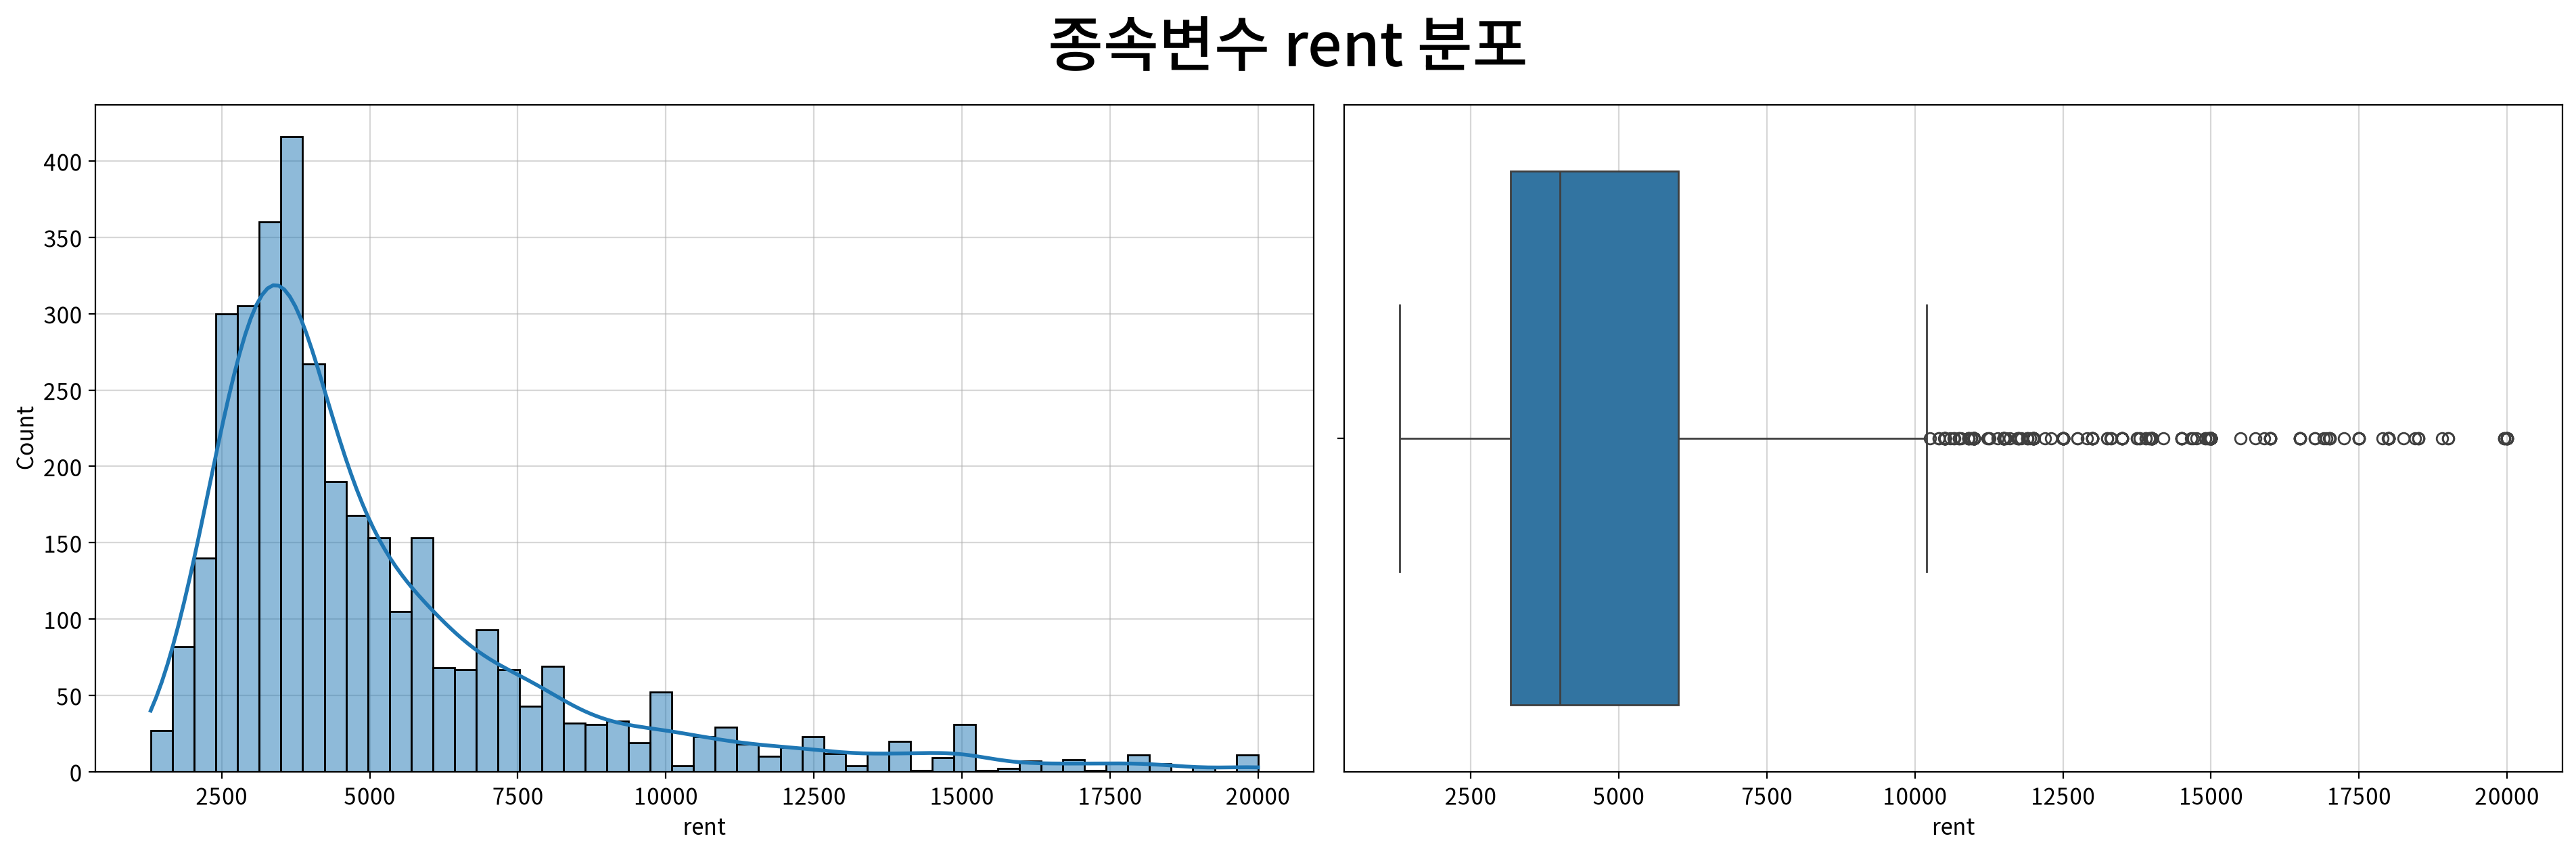

,rent
count,3512.000
mean,5142.887
std,3157.513
min,1300.000
25%,3169.250
50%,4000.000
75%,6000.000
max,20000.000
rel_diff,0.286
rdiff_flag,diff


In [12]:
## 종속변수
target = "rent"

## 1행 2열 서브플롯 구성
## -> 그래프 크기는 서브플롯 중 하나의 크기(전체 크기는 가로 960 x 2가 됨)
fig, ax = my_plot.init(rows=1, cols=2,
            title=f"종속변수 {target} 분포", width=960, height=640)
my_plot.histplot(data=df2, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df2, x=target, ax=ax[1])
my_plot.show()

## 연속형 변수 기술통계량에서 종속변수에 대한 부분만 추출
num_desc[num_desc.index == target].T

## #미션2. "어떤 변수가 회귀를 방해할까?"

- **평균과 중앙값의 거리:** 모든 변수에서 평균이 중앙값보다 높다. 특히 `rent(임대료)`는 평균 약 5,139달러와 중앙값 4,000달러의 차이가 커서 평균만으로는 일반적인 매물의 임대료를 설명하기가 어렵다 
- **왜도(skew):** `min_to_subway(지하철 도보 시간)`의 왜도가 4.842로 가장 높아 일부 매물의 도보 시간이 다른 매물보다 훨씬 시간이 걸리며, `building_age_yrs(건물 연수)`는 왜도가 0.419로 한쪽으로 치우친 정도가 비교적 작다
- **첨도(kurt):** `min_to_subway(지하철 도보 시간)`의 첨도가 30.003으로 가장 높아 극단적으로 큰 값이 보이며,  `rent(임대료)`와 `size_sqft(면적)`도 각각 4.318, 4.417로 비교적 큰 값의 영향이 보인다
- **이상치 비율** `rent(임대료)`가 7.7%로 가장 높고 `size_sqft(면적)` 5.1%, `floor(층수)` 4.2% 순서이며, 확인된 이상치는 모두 상단에 있지만 실제 매물의 특성일수도 있다고 판단하여 오류로 생각하지 않는다

- 네 지표를 함께 보면, `rent(임대료)` · `size_sqft(면적)` · `min_to_subway(지하철 도보 시간)` · `floor(층수)`에서 평균과 중앙값의 차이, 오른쪽 치우침(right_tail), 높은 첨도와 상단 이상치가 함께 나타나는 것을 볼 수 있다

- 종속변수 `rent`의 분포를 확인하면 **뚜렷한 우측 꼬리 분포**가 확인된다 
    - 히스토그램에서도 대부분의 매물이 낮은 임대료 구간에 집중되어 있고, 일부 고가 매물이 오른쪽으로 긴 꼬리를 형성하고 있다 
    - IQR 기준 상한 이상치는 **271건(7.7%)**이며 4.343으로 고가 임대료가 분포의 꼬리에 집중되어 있음을 확인할 수 있다
    - 따라서 `rent`는 **`log1p`** 변환 후보로 선정하며
        - 로그 변환을 통해 **고가 임대료의 영향과 분포의 비대칭을 완화**하기 위함 

---

## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 분포 확인

##### 1) 타입 변환 (명목형 확정)

명목형 기술통계량 표의 컬럼명이 명목형 변수 목록이다.

In [13]:
df = my_qtcheck.set_type(df2, as_category=cat_desc.columns)

<class 'pandas.core.frame.DataFrame'>
Index: 3512 entries, 0 to 3538
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   rent              3512 non-null   int64   
 1   bedrooms          3512 non-null   float64 
 2   bathrooms         3512 non-null   int64   
 3   size_sqft         3512 non-null   int64   
 4   min_to_subway     3512 non-null   int64   
 5   floor             3512 non-null   float64 
 6   building_age_yrs  3512 non-null   int64   
 7   no_fee            3512 non-null   category
 8   has_roofdeck      3512 non-null   category
 9   has_washer_dryer  3512 non-null   category
 10  has_doorman       3512 non-null   category
 11  has_elevator      3512 non-null   category
 12  has_dishwasher    3512 non-null   category
 13  has_patio         3512 non-null   category
 14  has_gym           3512 non-null   category
 15  neighborhood      3512 non-null   category
dtypes: category(9), float64(2), i

##### 2) 변수 유형 분류

In [14]:
## 종속변수
target = "rent"
## 종속변수 연속형 여부
target_is_continuous = True

## 명목형 변수
nominal_cols = my_qtcheck.get_categorical_column_names(df)
## 연속형 변수
continuous_cols = my_qtcheck.get_number_column_names(df)

if target_is_continuous:
    ## 연속형 변수 이름에서 종속변수 항목 제거
    continuous_cols.remove(target)
else:
    ## 명목형 변수 이름에서 종속변수 항목 제거
    nominal_cols.remove(target)

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : rent
종속변수 유형: 연속형
명목형   : ['no_fee', 'has_roofdeck', 'has_washer_dryer', 'has_doorman', 'has_elevator', 'has_dishwasher', 'has_patio', 'has_gym', 'neighborhood']
연속형   : ['bedrooms', 'bathrooms', 'size_sqft', 'min_to_subway', 'floor', 'building_age_yrs']


##### 3) 컬럼 의미를 정리한 딕셔너리

In [15]:
column_means = {
    "rent":             "월 임대료(USD/월)",
    "bedrooms":         "침실 수(개)",              
    "bathrooms":        "욕실 수(개)",              
    "size_sqft":        "전용 면적(sqft)",
    "min_to_subway":    "지하철역까지 도보 시간(분)",
    "floor":            "매물이 위치한 층",          
    "building_age_yrs": "건물 준공 후 경과 연수(년)", 
    "no_fee":           "중개 수수료 없음 여부",     
    "has_roofdeck":     "옥상 데크 보유 여부",       
    "has_washer_dryer": "세대 내 세탁기·건조기 보유 여부",
    "has_doorman":      "도어맨 배치 여부",          
    "has_elevator":     "엘리베이터 보유 여부",
    "has_dishwasher":   "식기세척기 보유 여부",
    "has_patio":        "파티오(테라스·발코니) 보유 여부",
    "has_gym":          "건물 내 헬스장 보유 여부",
    "neighborhood":     "매물이 속한 세부 동네명"             
}

##### 4) EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 수치형 | 상관분석 | 수치형 독립변수 6종 ↔ `rent` | ✅ 적용 | 이산형 수치 변수 포함 |
| 연속형 | 명목형(2집단) | T검정 | 이진 명목형 독립변수 8종 → `rent` | ✅ 적용 | 각 변수의 0·1 집단 간 평균 임대료 비교 |
| 연속형 | 명목형(3집단+) | ANOVA | `neighborhood` → `rent` | ✅ 적용 | 32개 동네 간 평균 임대료 비교 |
| 명목형(2집단) | 연속형 | T검정 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |

- 종속변수 `rent(임대료)`가 연속형이며, 독립변수 유형에 따라 Spearman 상관분석·Mann–Whitney U 검정·Welch ANOVA를 적용한다.
- **수치형 독립변수 6종:** `bedrooms`, `bathrooms`, `size_sqft`, `min_to_subway`, `floor`, `building_age_yrs`
- **이진 명목형 독립변수 8종:** `no_fee`, `has_roofdeck`, `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`, `has_patio`, `has_gym`
- **3집단 이상 명목형 독립변수 1종:** `neighborhood`(32개 수준)

#### 4-2. 변수 간 관계

##### 1) 상관분석 (x: 연속형 독립변수 → y: 연속형 종속변수)

##### ▶︎ bedrooms(침실 수(개)) → rent

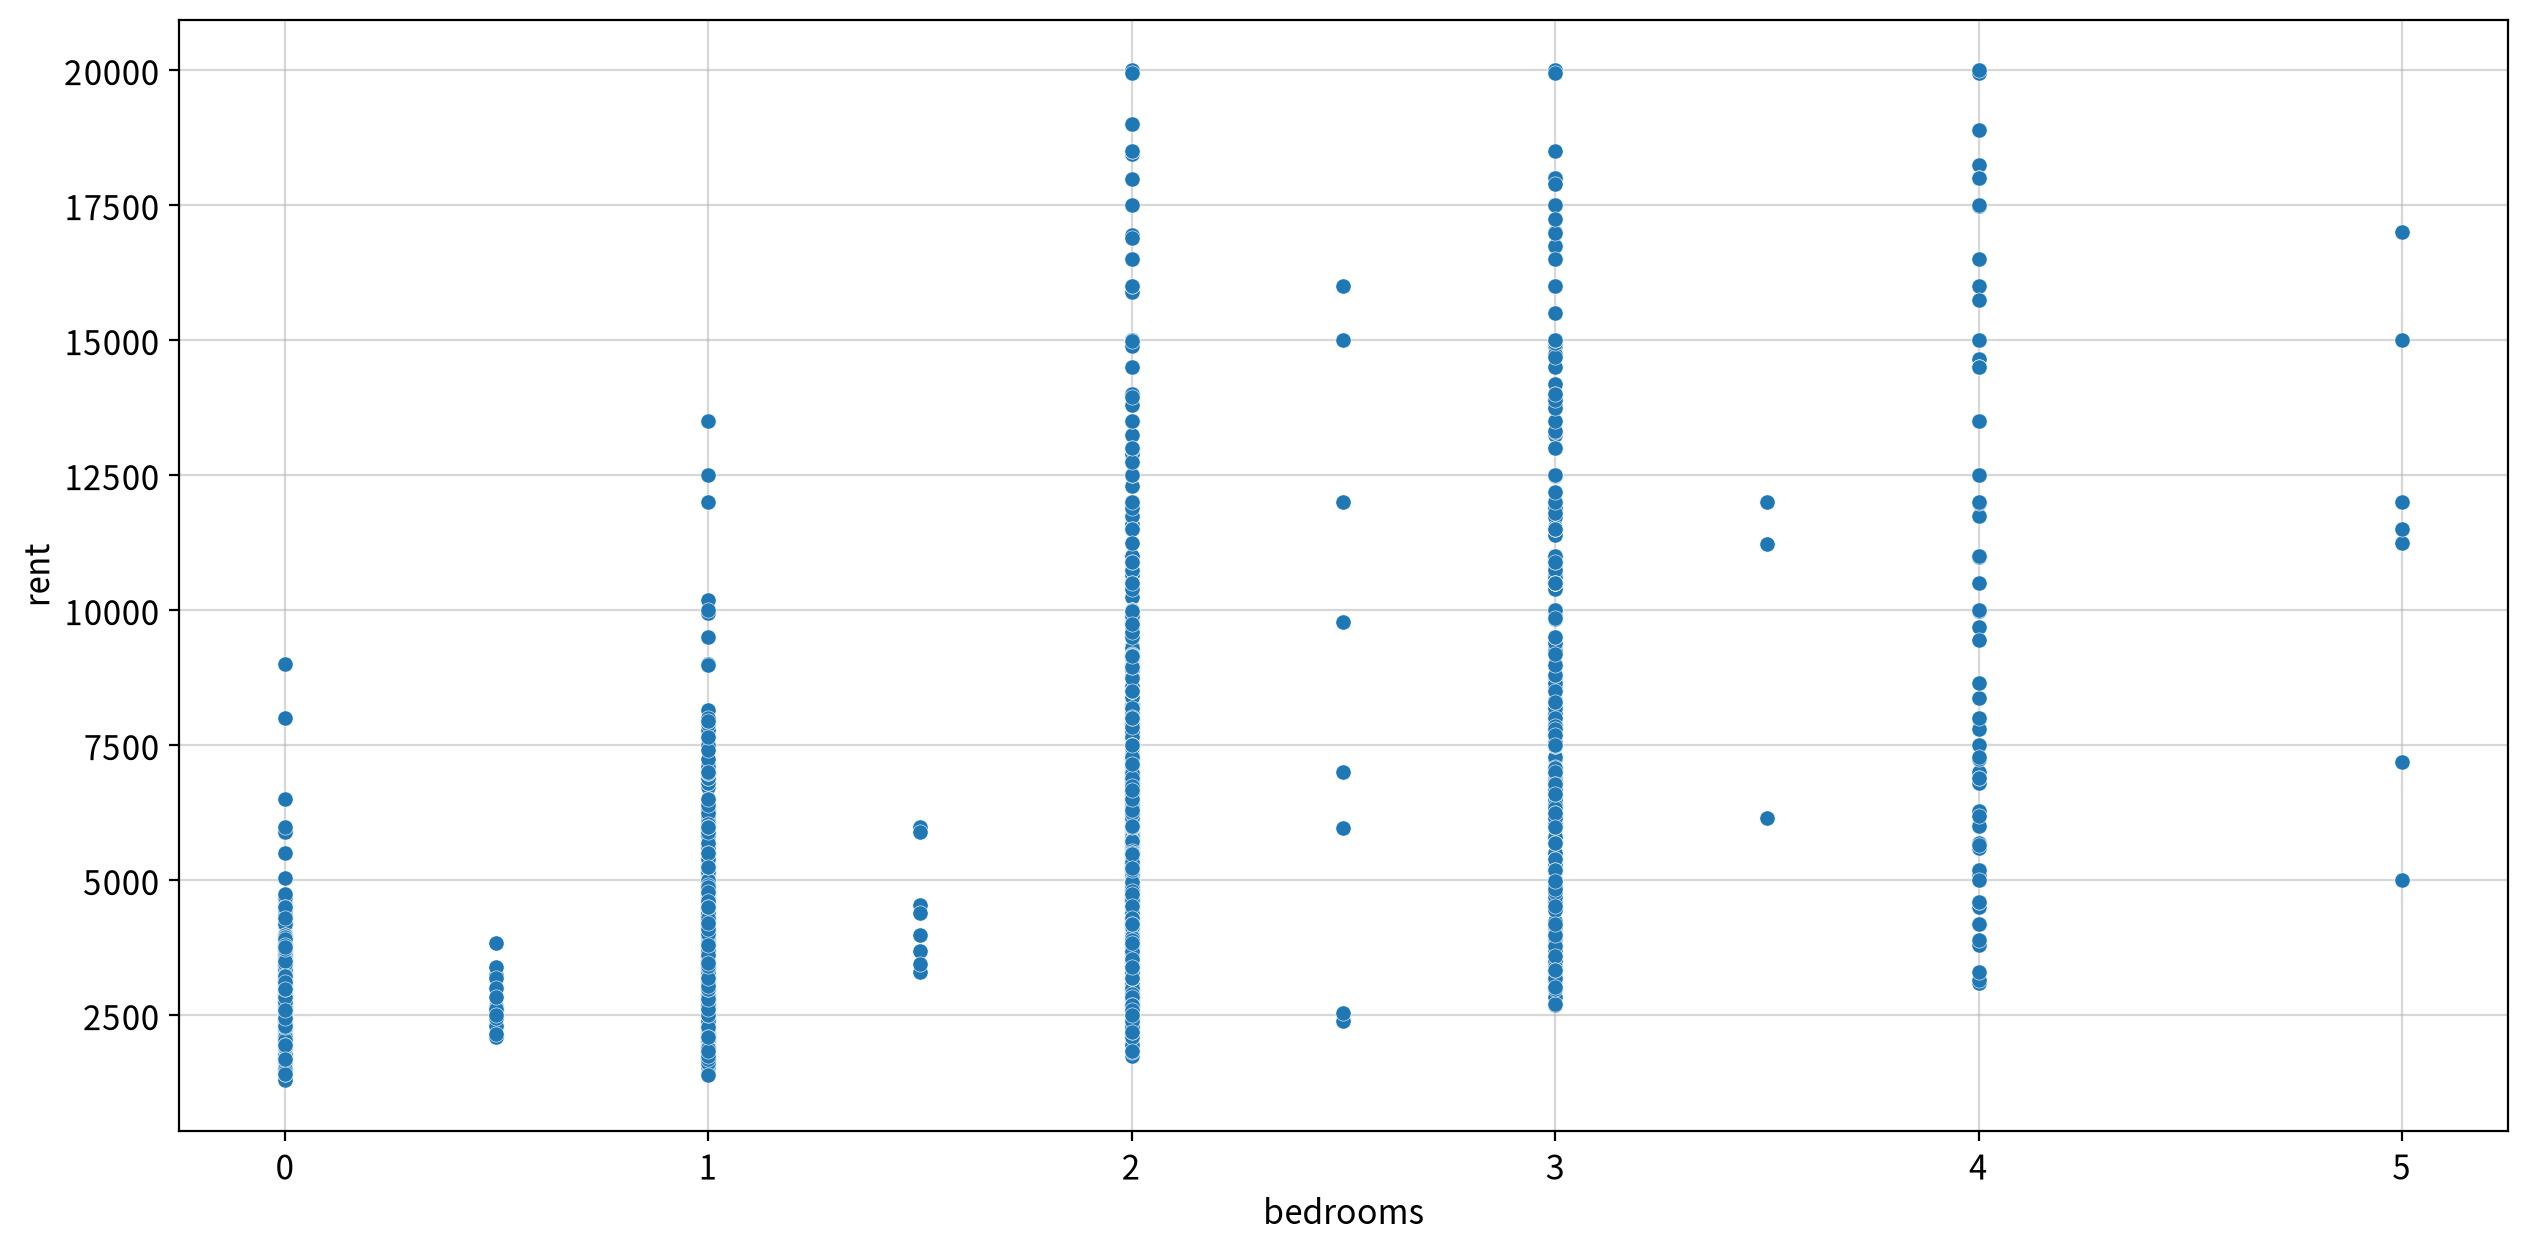

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
bedrooms,rent,Spearman,0.678,0.000,Moderate,True,False,False,False,True


##### ▶︎ bathrooms(욕실 수(개)) → rent

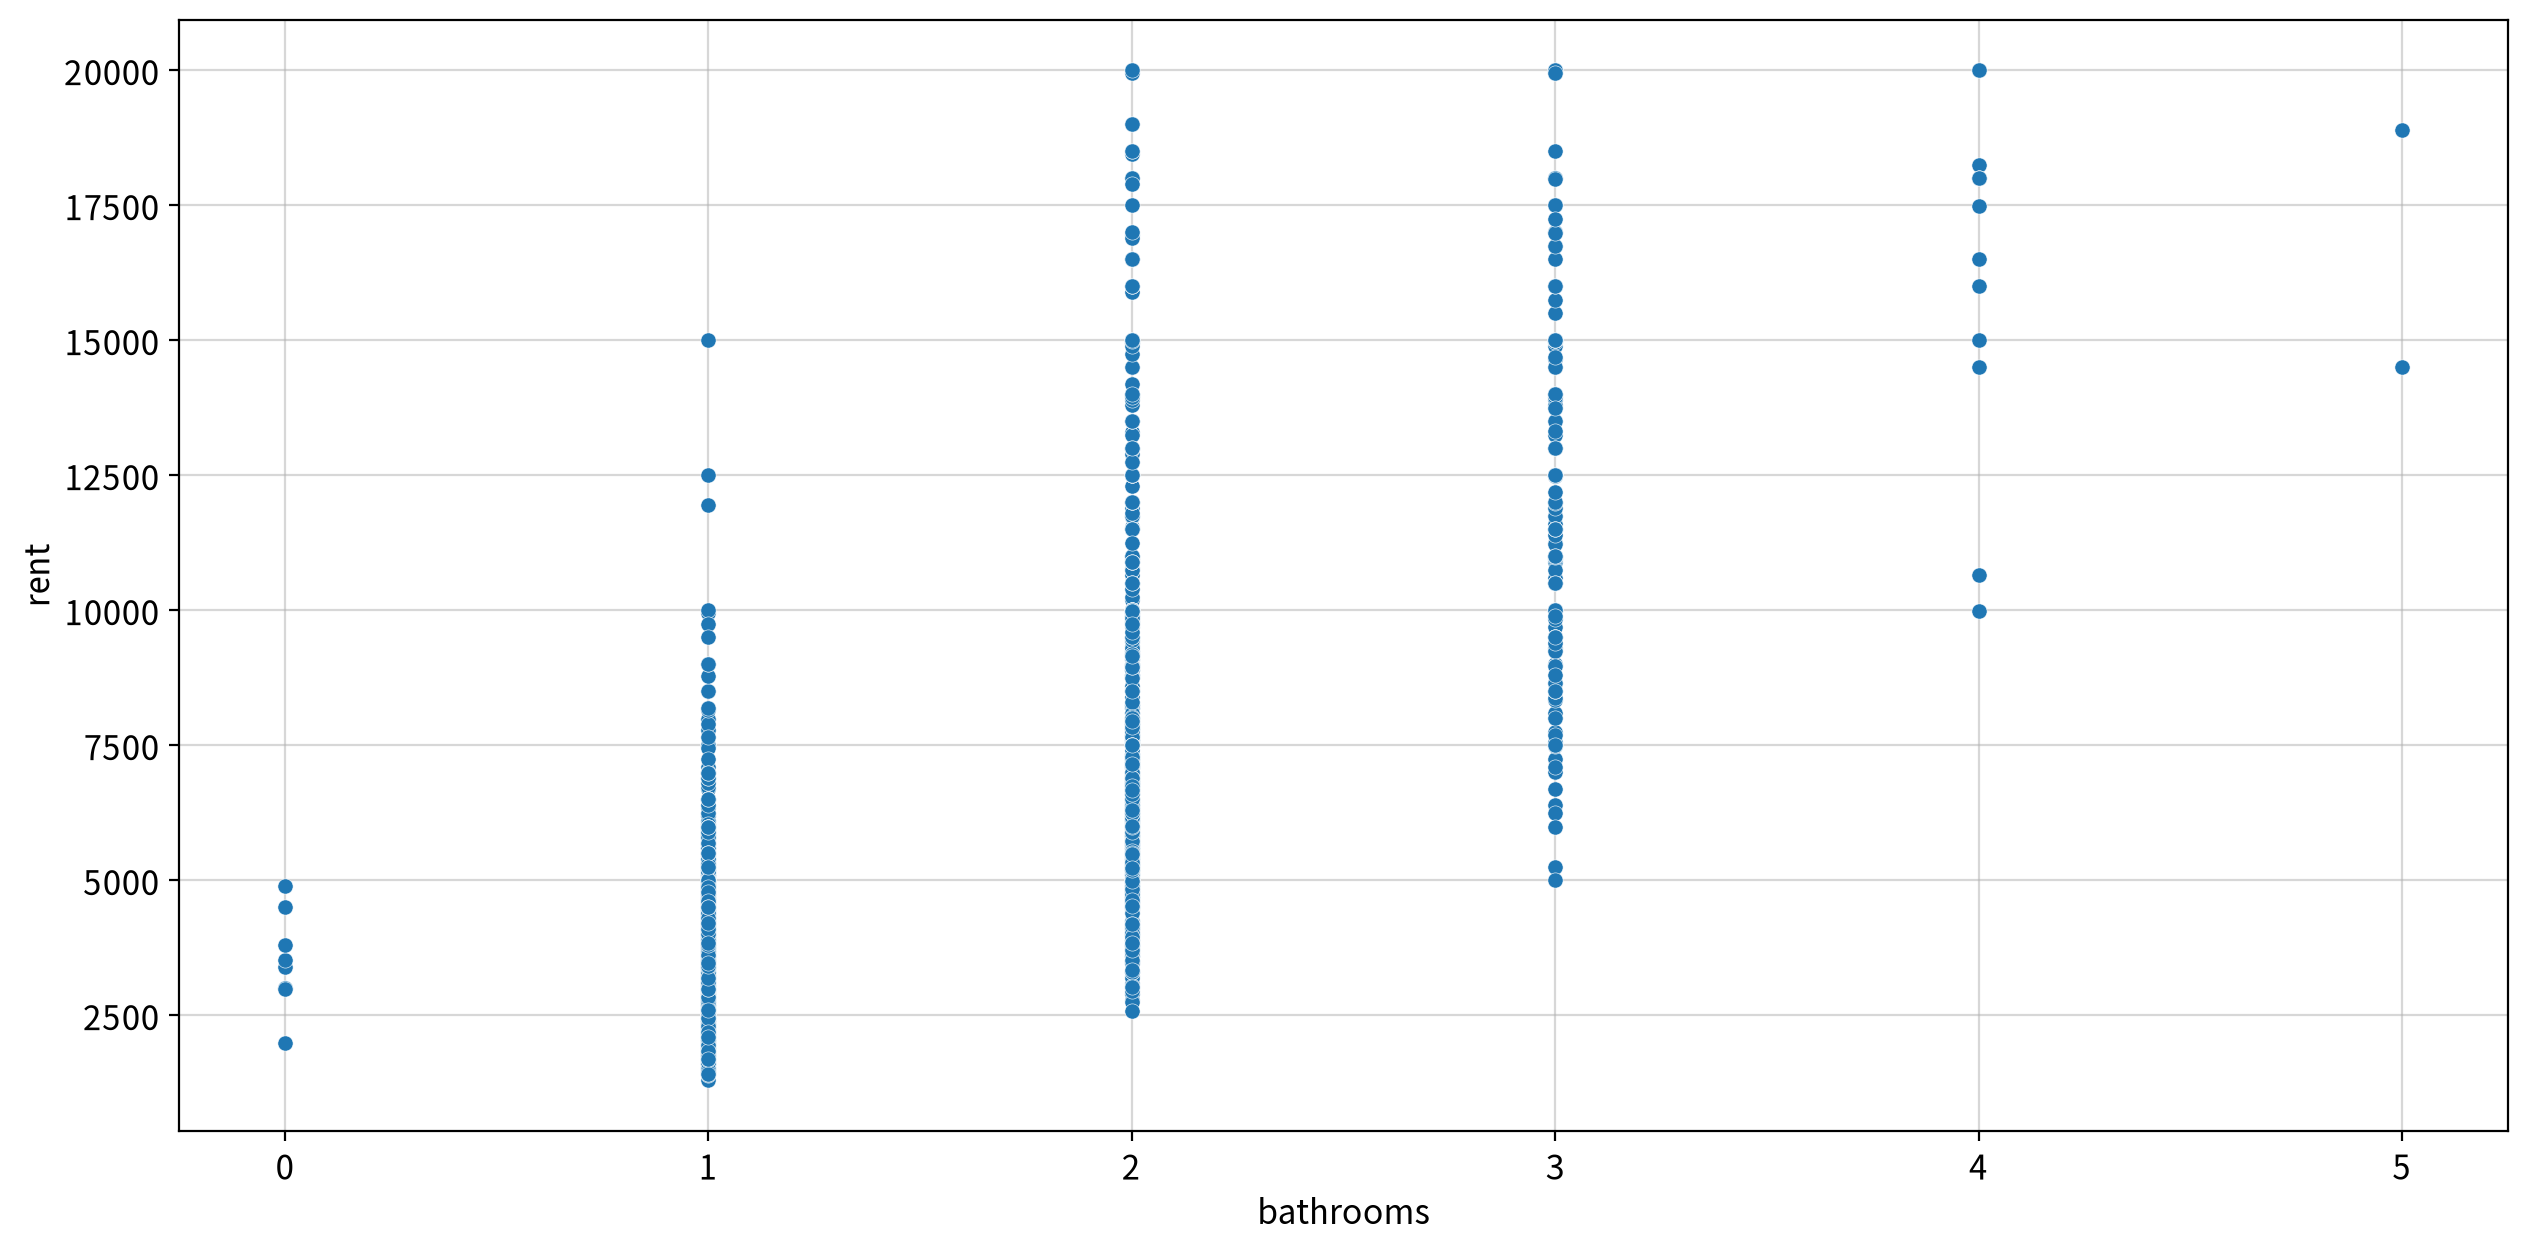

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
bathrooms,rent,Spearman,0.722,0.000,Strong,True,False,False,False,True


##### ▶︎ size_sqft(전용 면적(sqft)) → rent

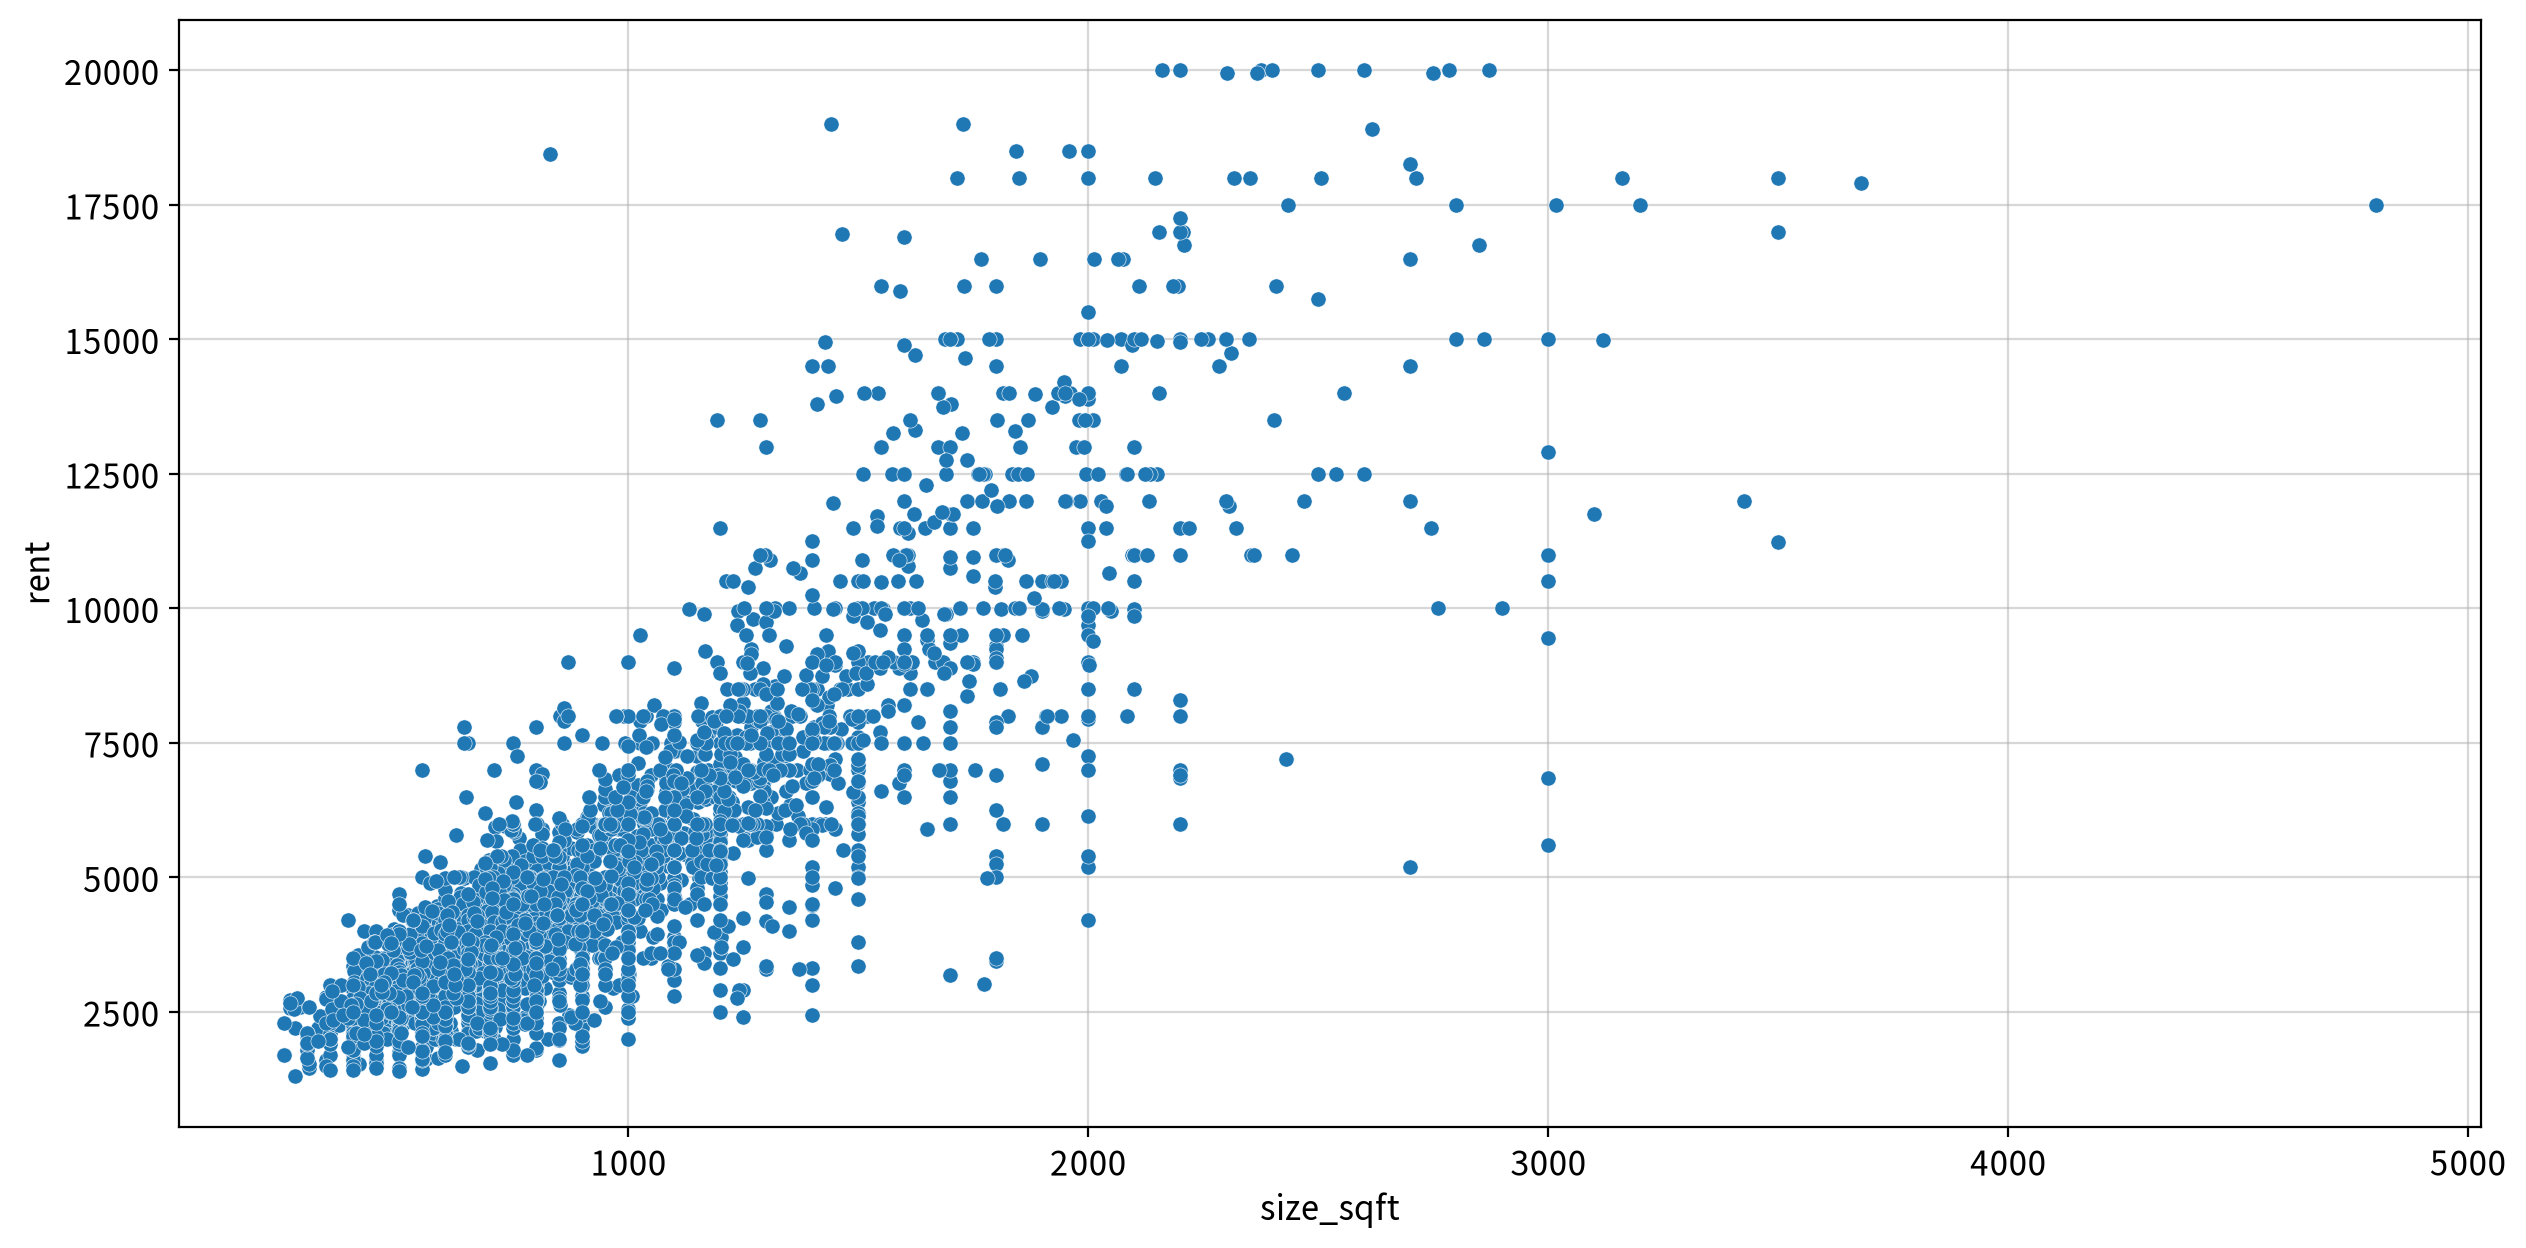

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
size_sqft,rent,Spearman,0.838,0.000,Strong,True,False,False,False,True


##### ▶︎ min_to_subway(지하철역까지 도보 시간(분)) → rent

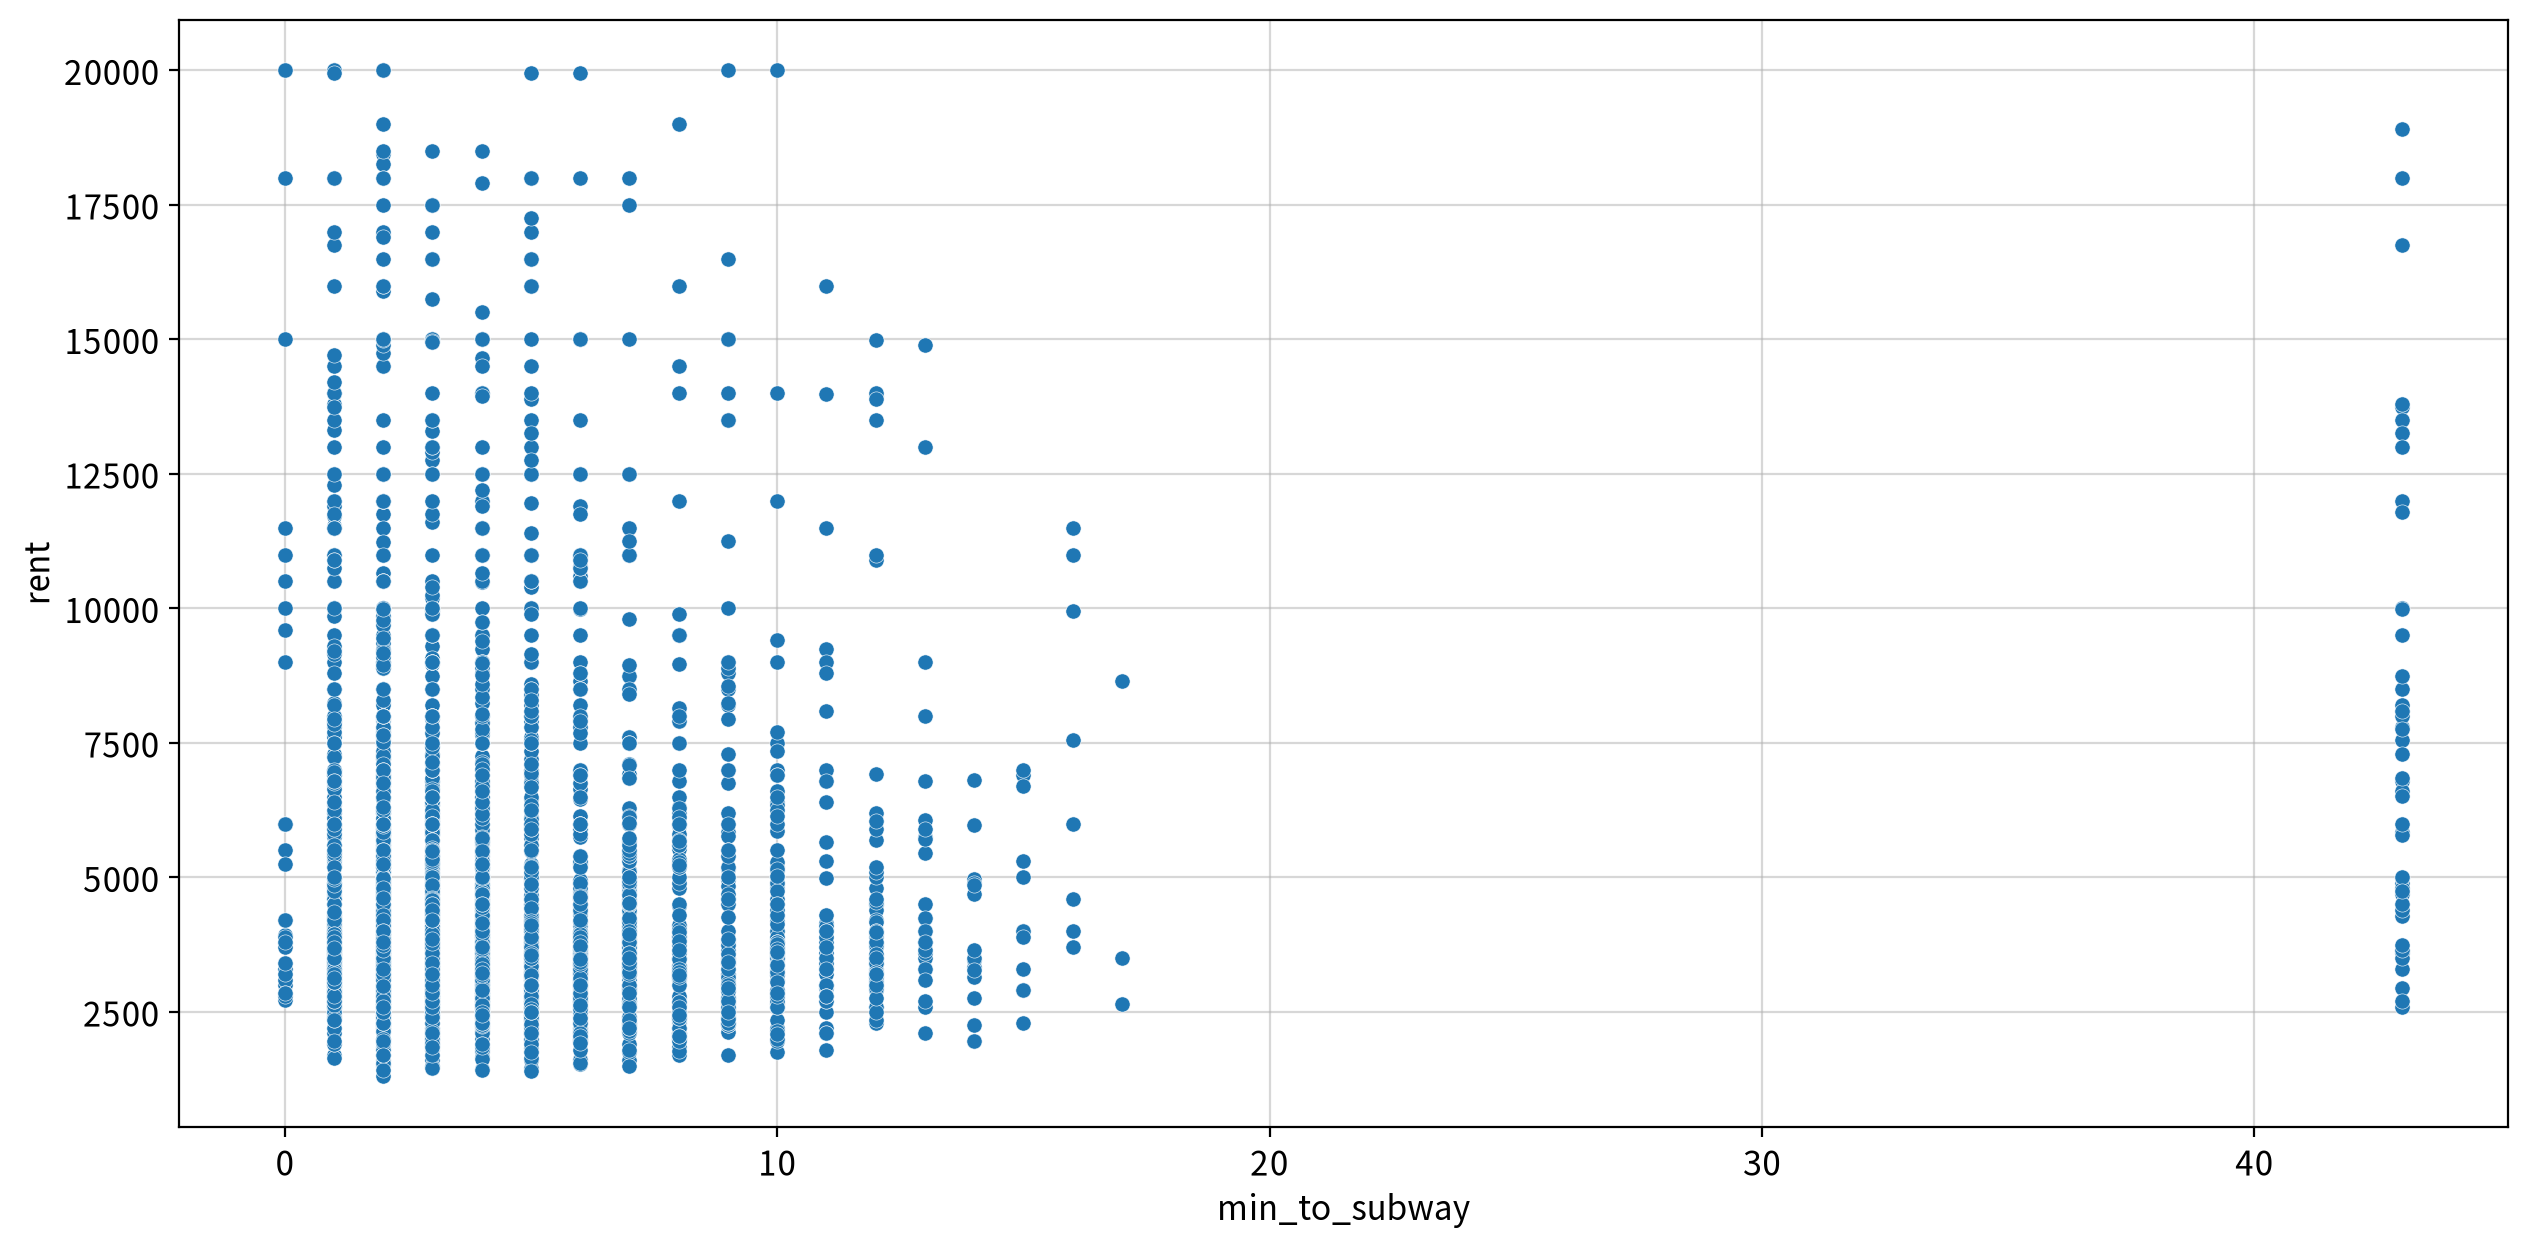

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
min_to_subway,rent,Spearman,-0.083,0.000,Weak,True,False,False,False,True


##### ▶︎ floor(매물이 위치한 층) → rent

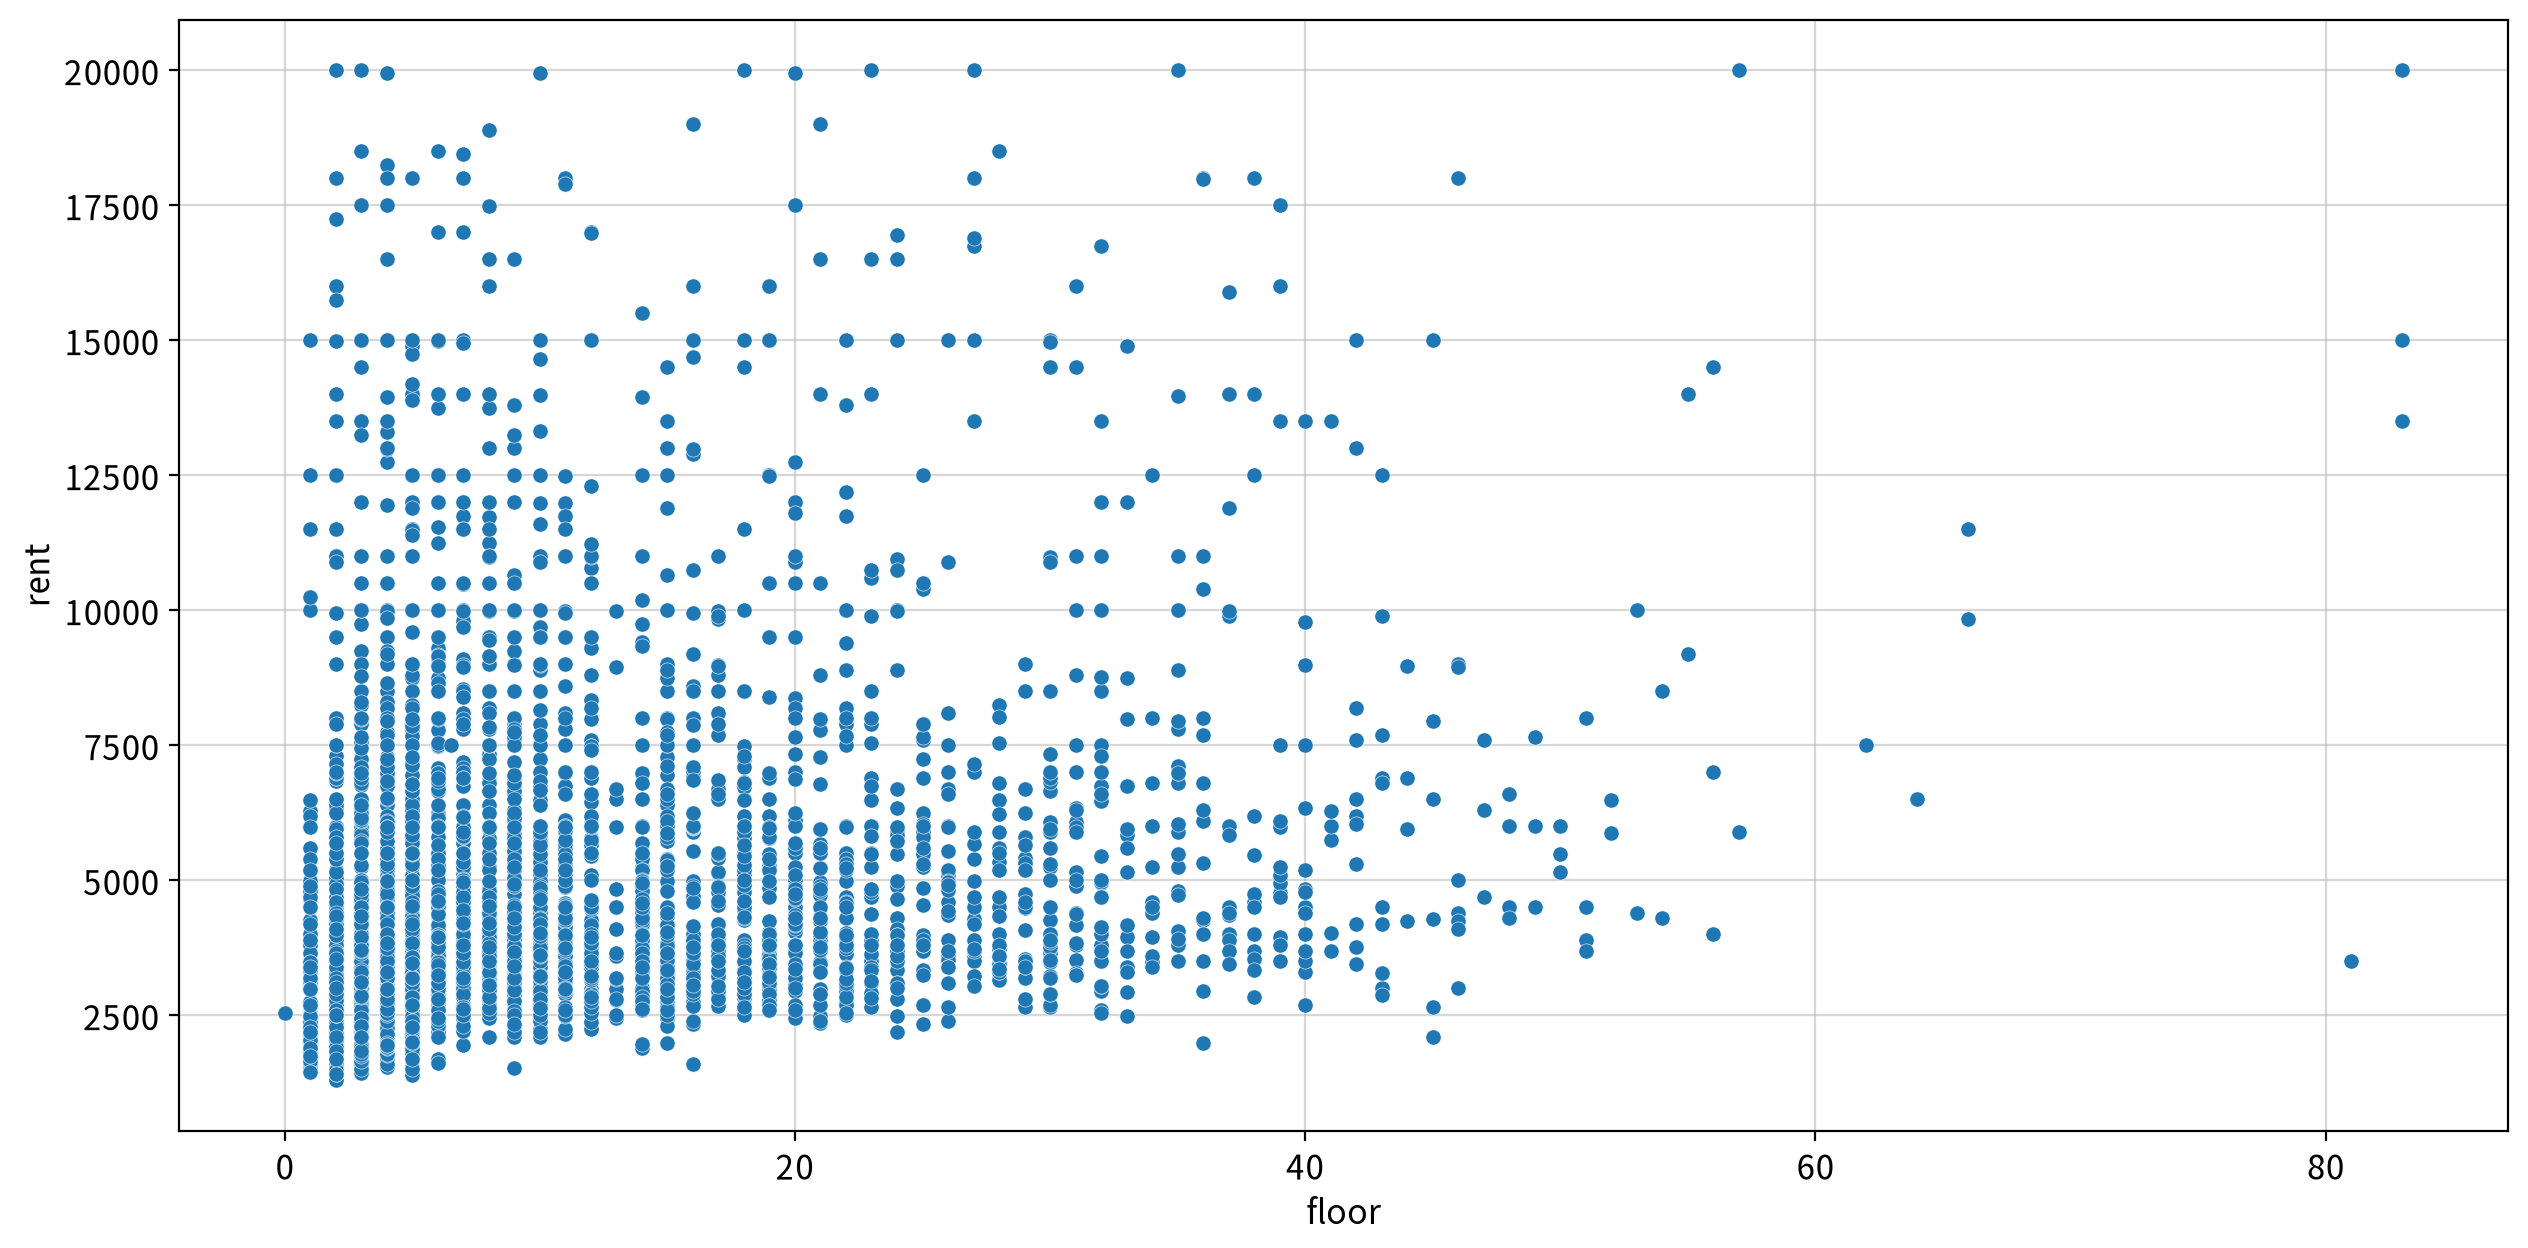

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
floor,rent,Spearman,0.300,0.000,Weak,True,False,False,True,True


##### ▶︎ building_age_yrs(건물 준공 후 경과 연수(년)) → rent

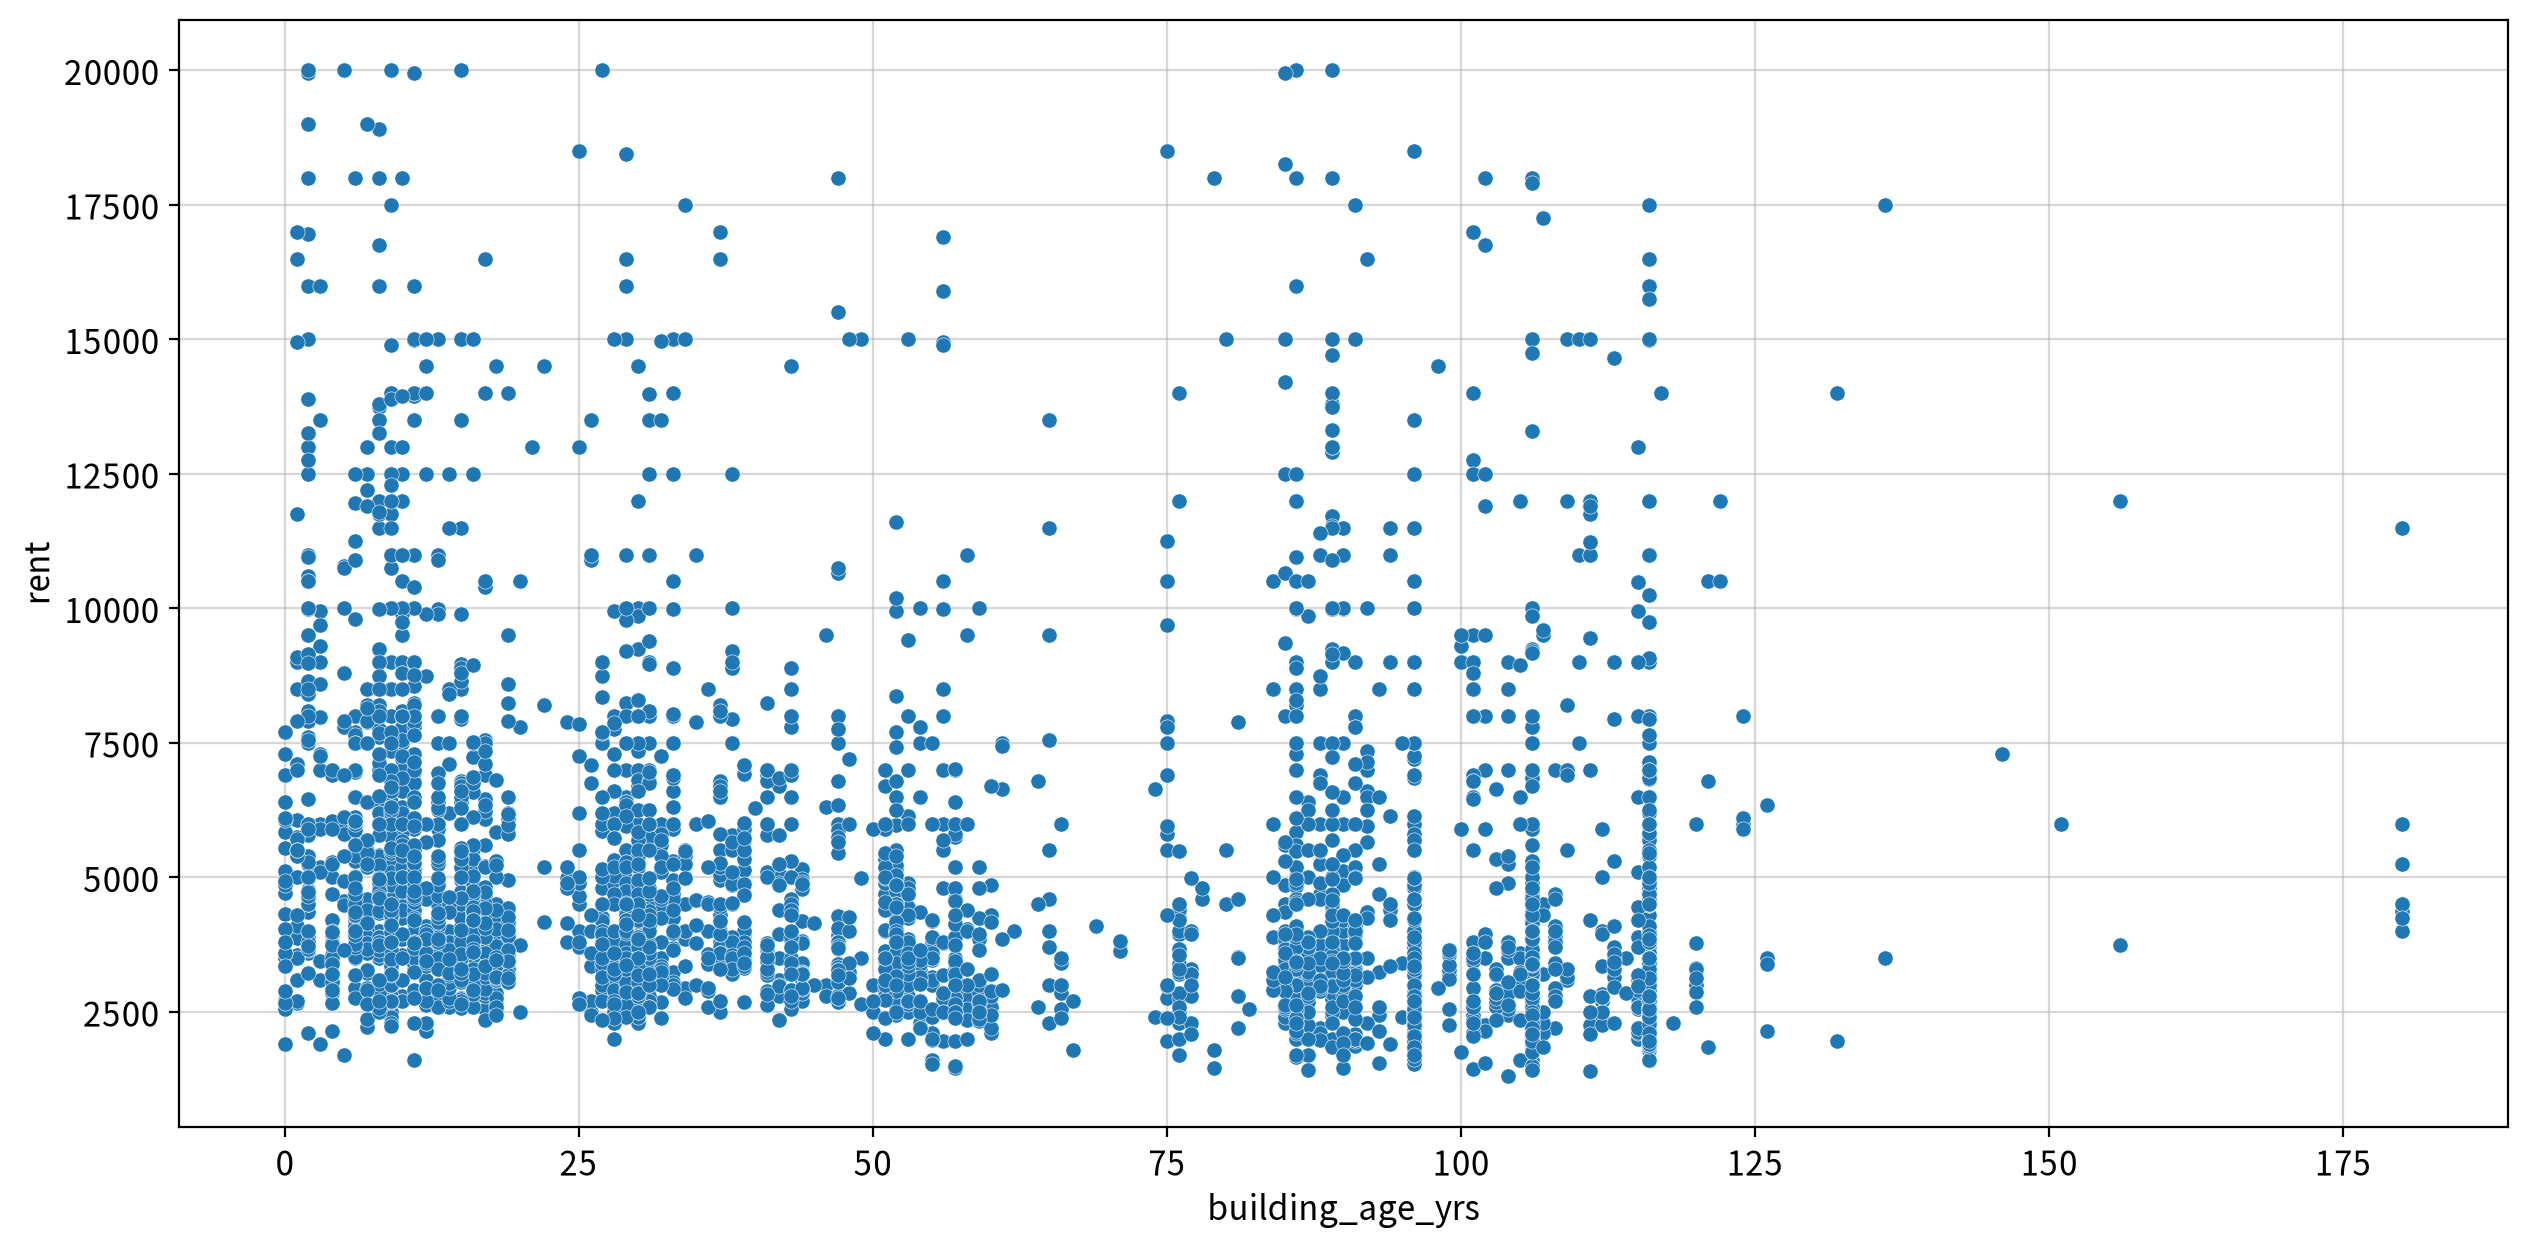

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
building_age_yrs,rent,Spearman,-0.253,0.000,Weak,True,False,False,False,True


In [17]:
## 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    ## 빈 줄 출력용
    print()

    ## 분석 단위 제목 출력
    display(Markdown(f"##### ▶︎ {f}({column_means[f]}) → {target}"))

    ## 시각화
    my_plot.scatterplot(data=df, x=f, y=target, outline=False,
                        ## 데이터 밀도에 따라 외곽선 굵기와 점 크기 조절
                        linewidth=0.2, size=30)

    ## my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(df, x=f, y=target, plot=False))

**해석**
- `bedrooms`는 ``rent``와 중간 정도의 양의 상관관계가 나타났다(coef=0.678, p<0.001)
- `bathrooms`와 `size_sqft`는 각각 `rent`와 강한 양의 상관관계가 나타났다(coef=0.838, p<0.001)
- `min_to_subway`는 `rent`와 매우 약한 음의 상관관계가 나타났다(coef=-0.083, p<0.001)
- `floor`는 `rent`와 약한 양의 상관관계가 나타났다(coef=0.300, p<0.001)
- `building_age_yrs`는 `rent`와 약한 음의 상관관계가 나타났다(coef=-0.253, p<0.001)
- 모든 변수에서 정규성 또는 선형성 가정이 충족되지 않아 Spearman 상관분석 결과를 기준으로 해석하였다

##### 2) T-Test (x: 2집단 명목형 독립변수 → y: 종속변수)

- 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.

##### ▶︎ no_fee(중개 수수료 없음 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.947e-01 U_stat=1.501e+06


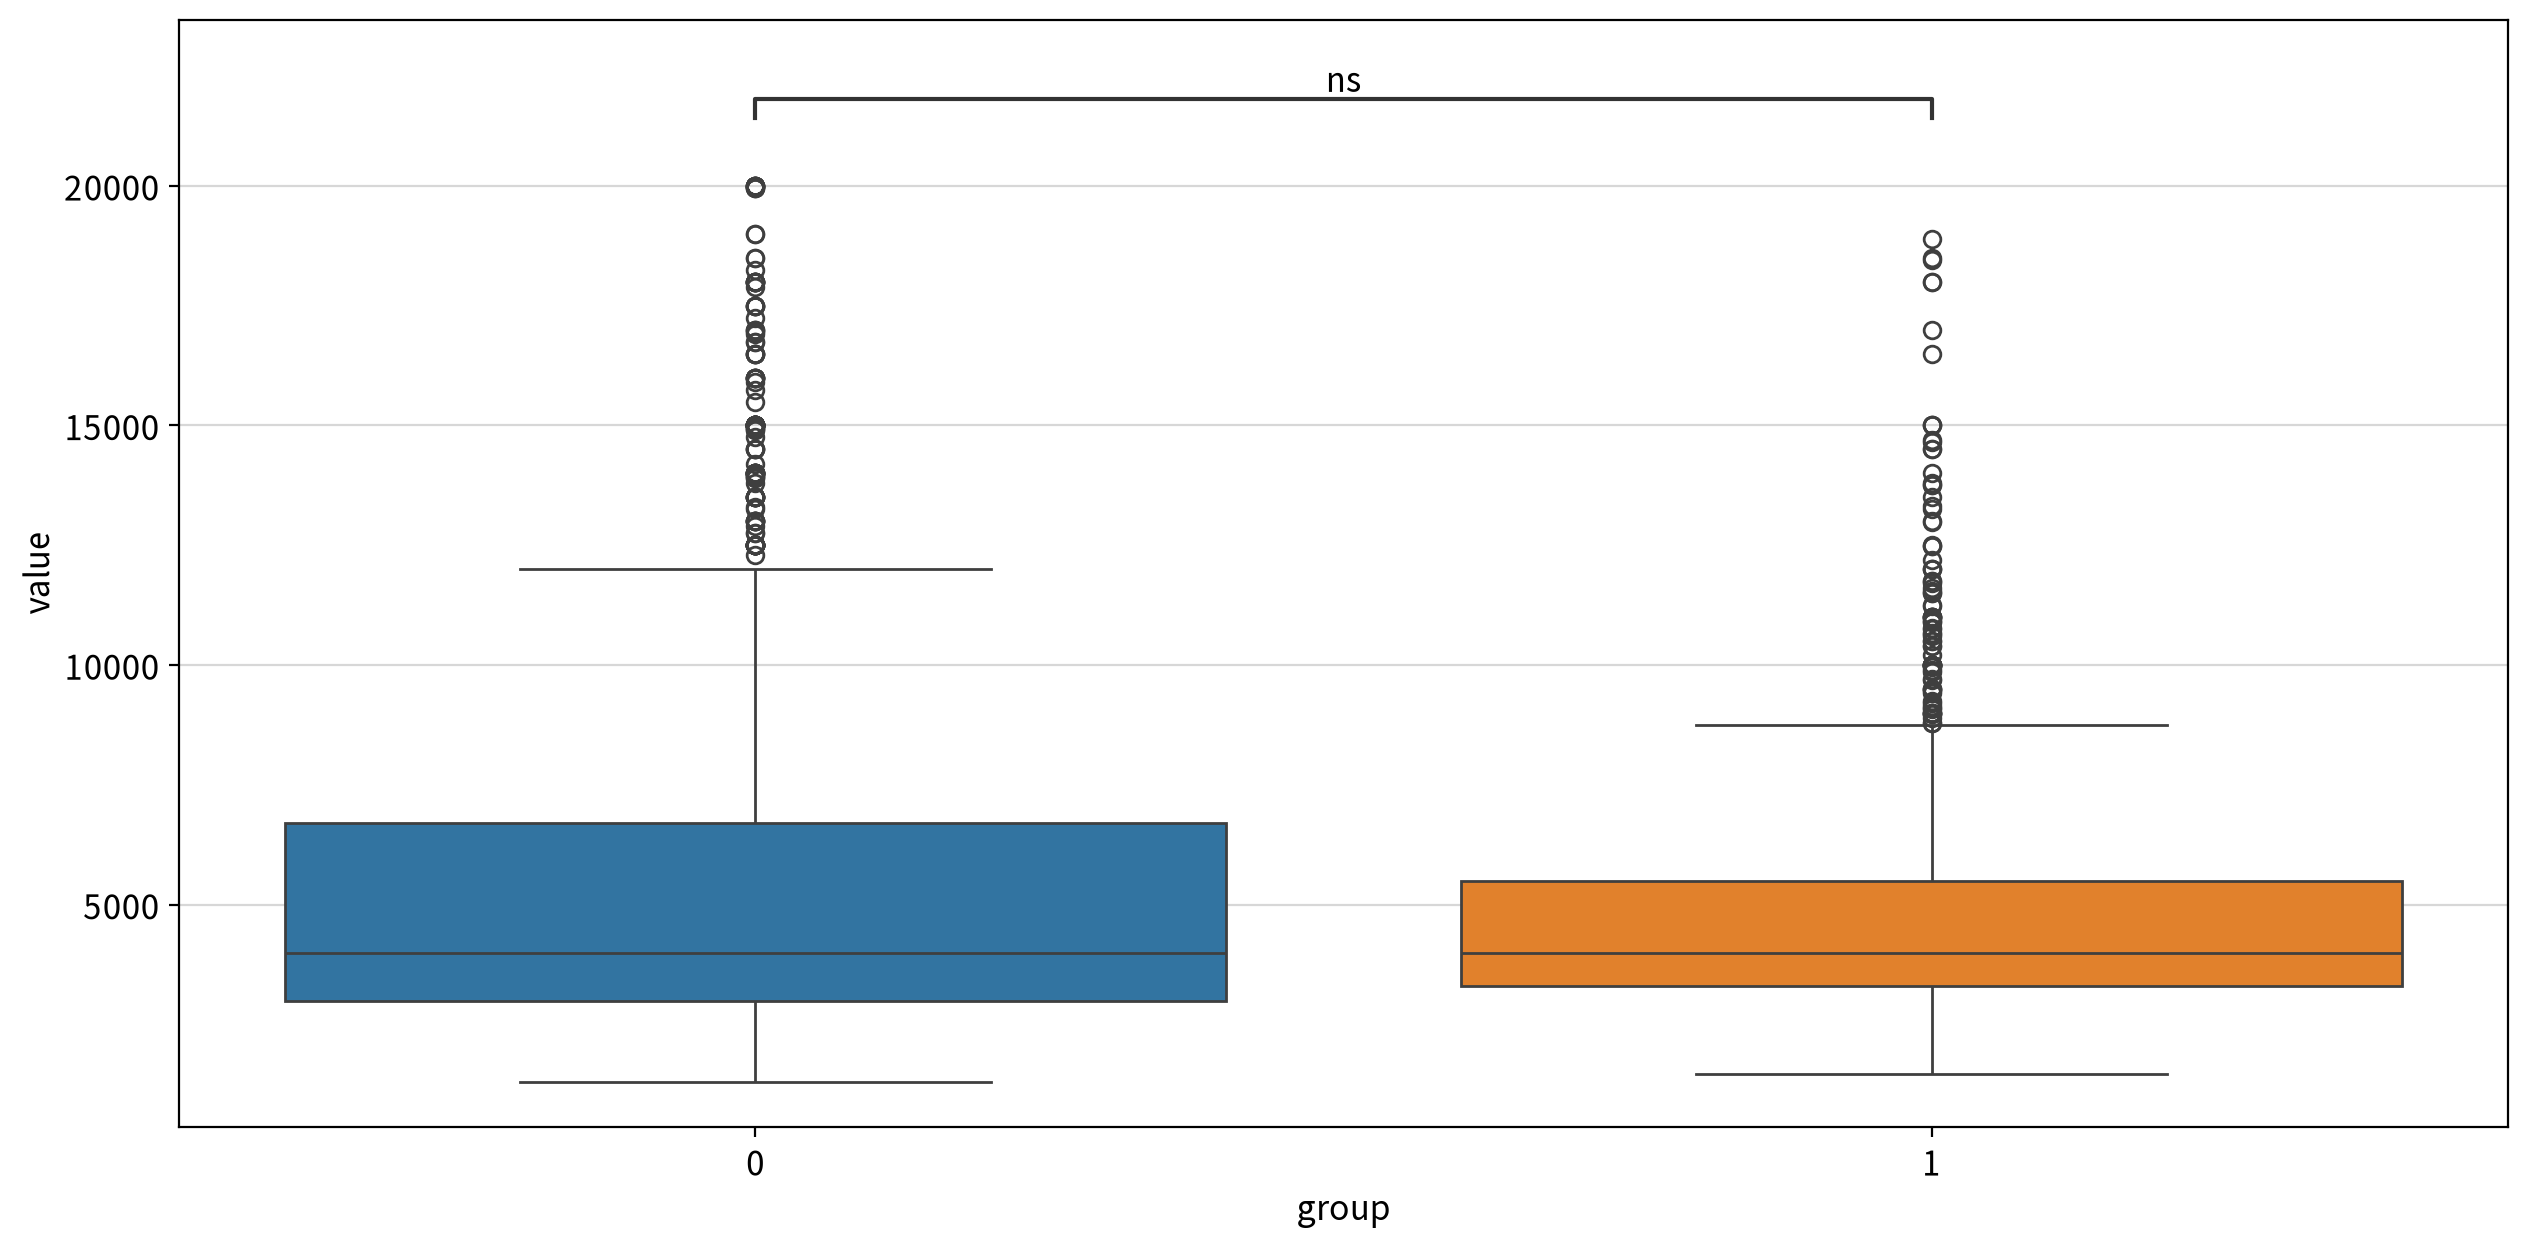

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1501349.000    0.595        False  0 = 1
                    less        1501349.000    0.703        False  0 ≥ 1
                    greater     1501349.000    0.297        False  0 ≤ 1

##### ▶︎ has_roofdeck(옥상 데크 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.714e-02 U_stat=7.671e+05


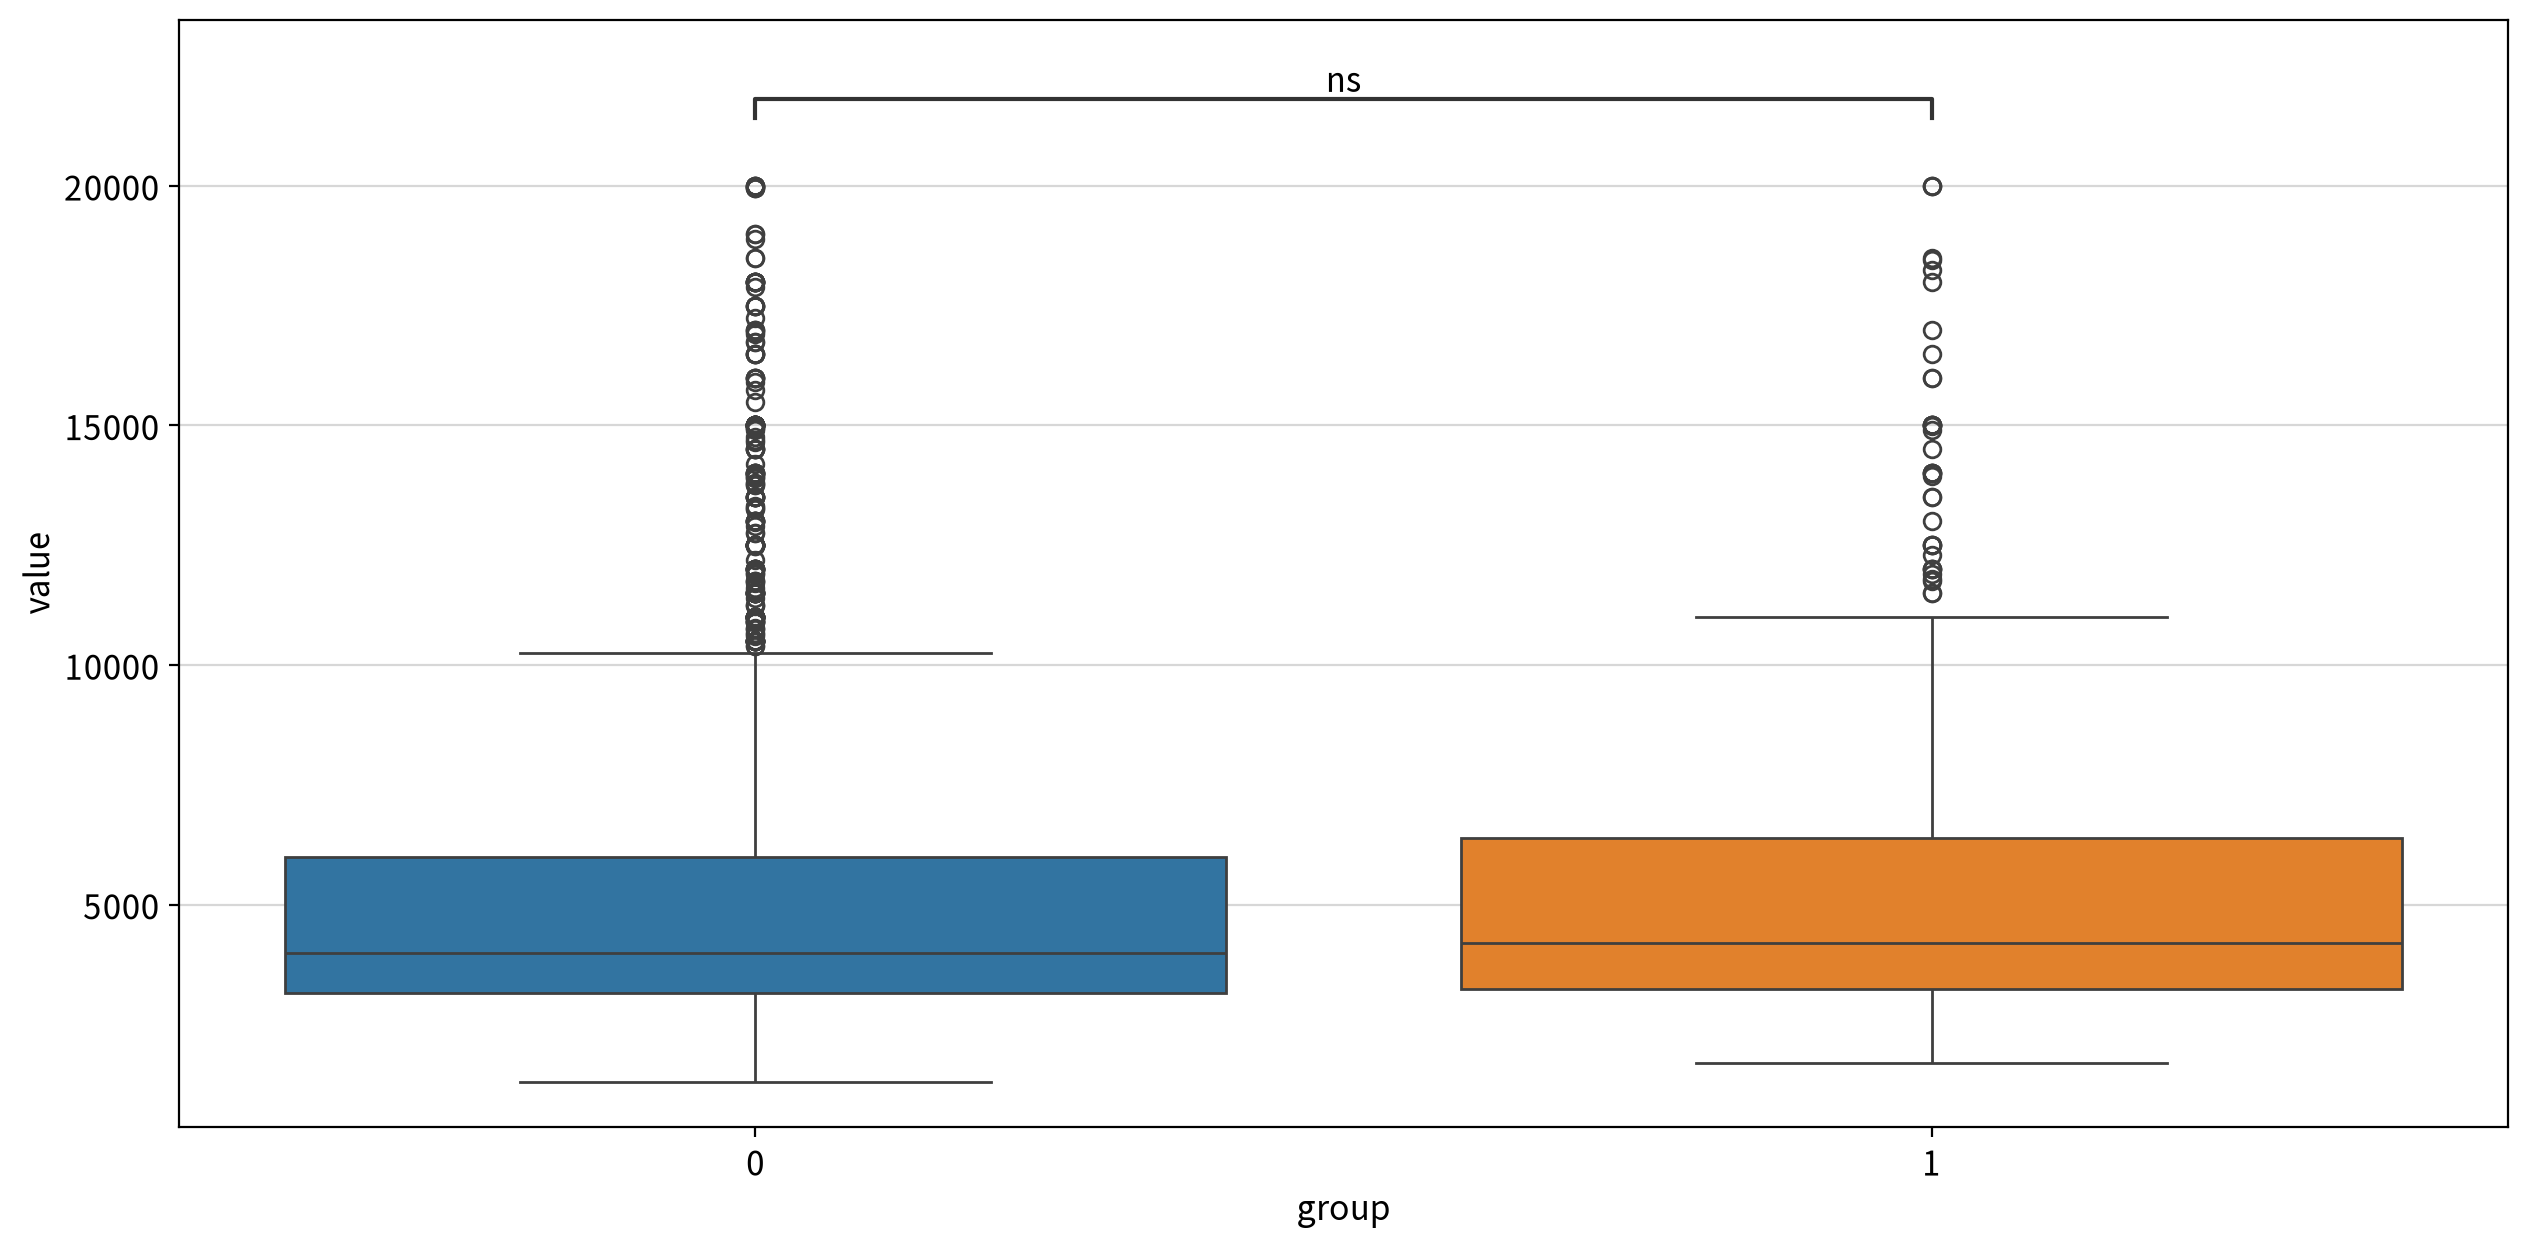

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   767120.500    0.057        False  0 = 1
                    less        767120.500    0.029         True  0 < 1
                    greater     767120.500    0.971        False  0 ≤ 1

##### ▶︎ has_washer_dryer(세대 내 세탁기·건조기 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.526e-04 U_stat=7.489e+05


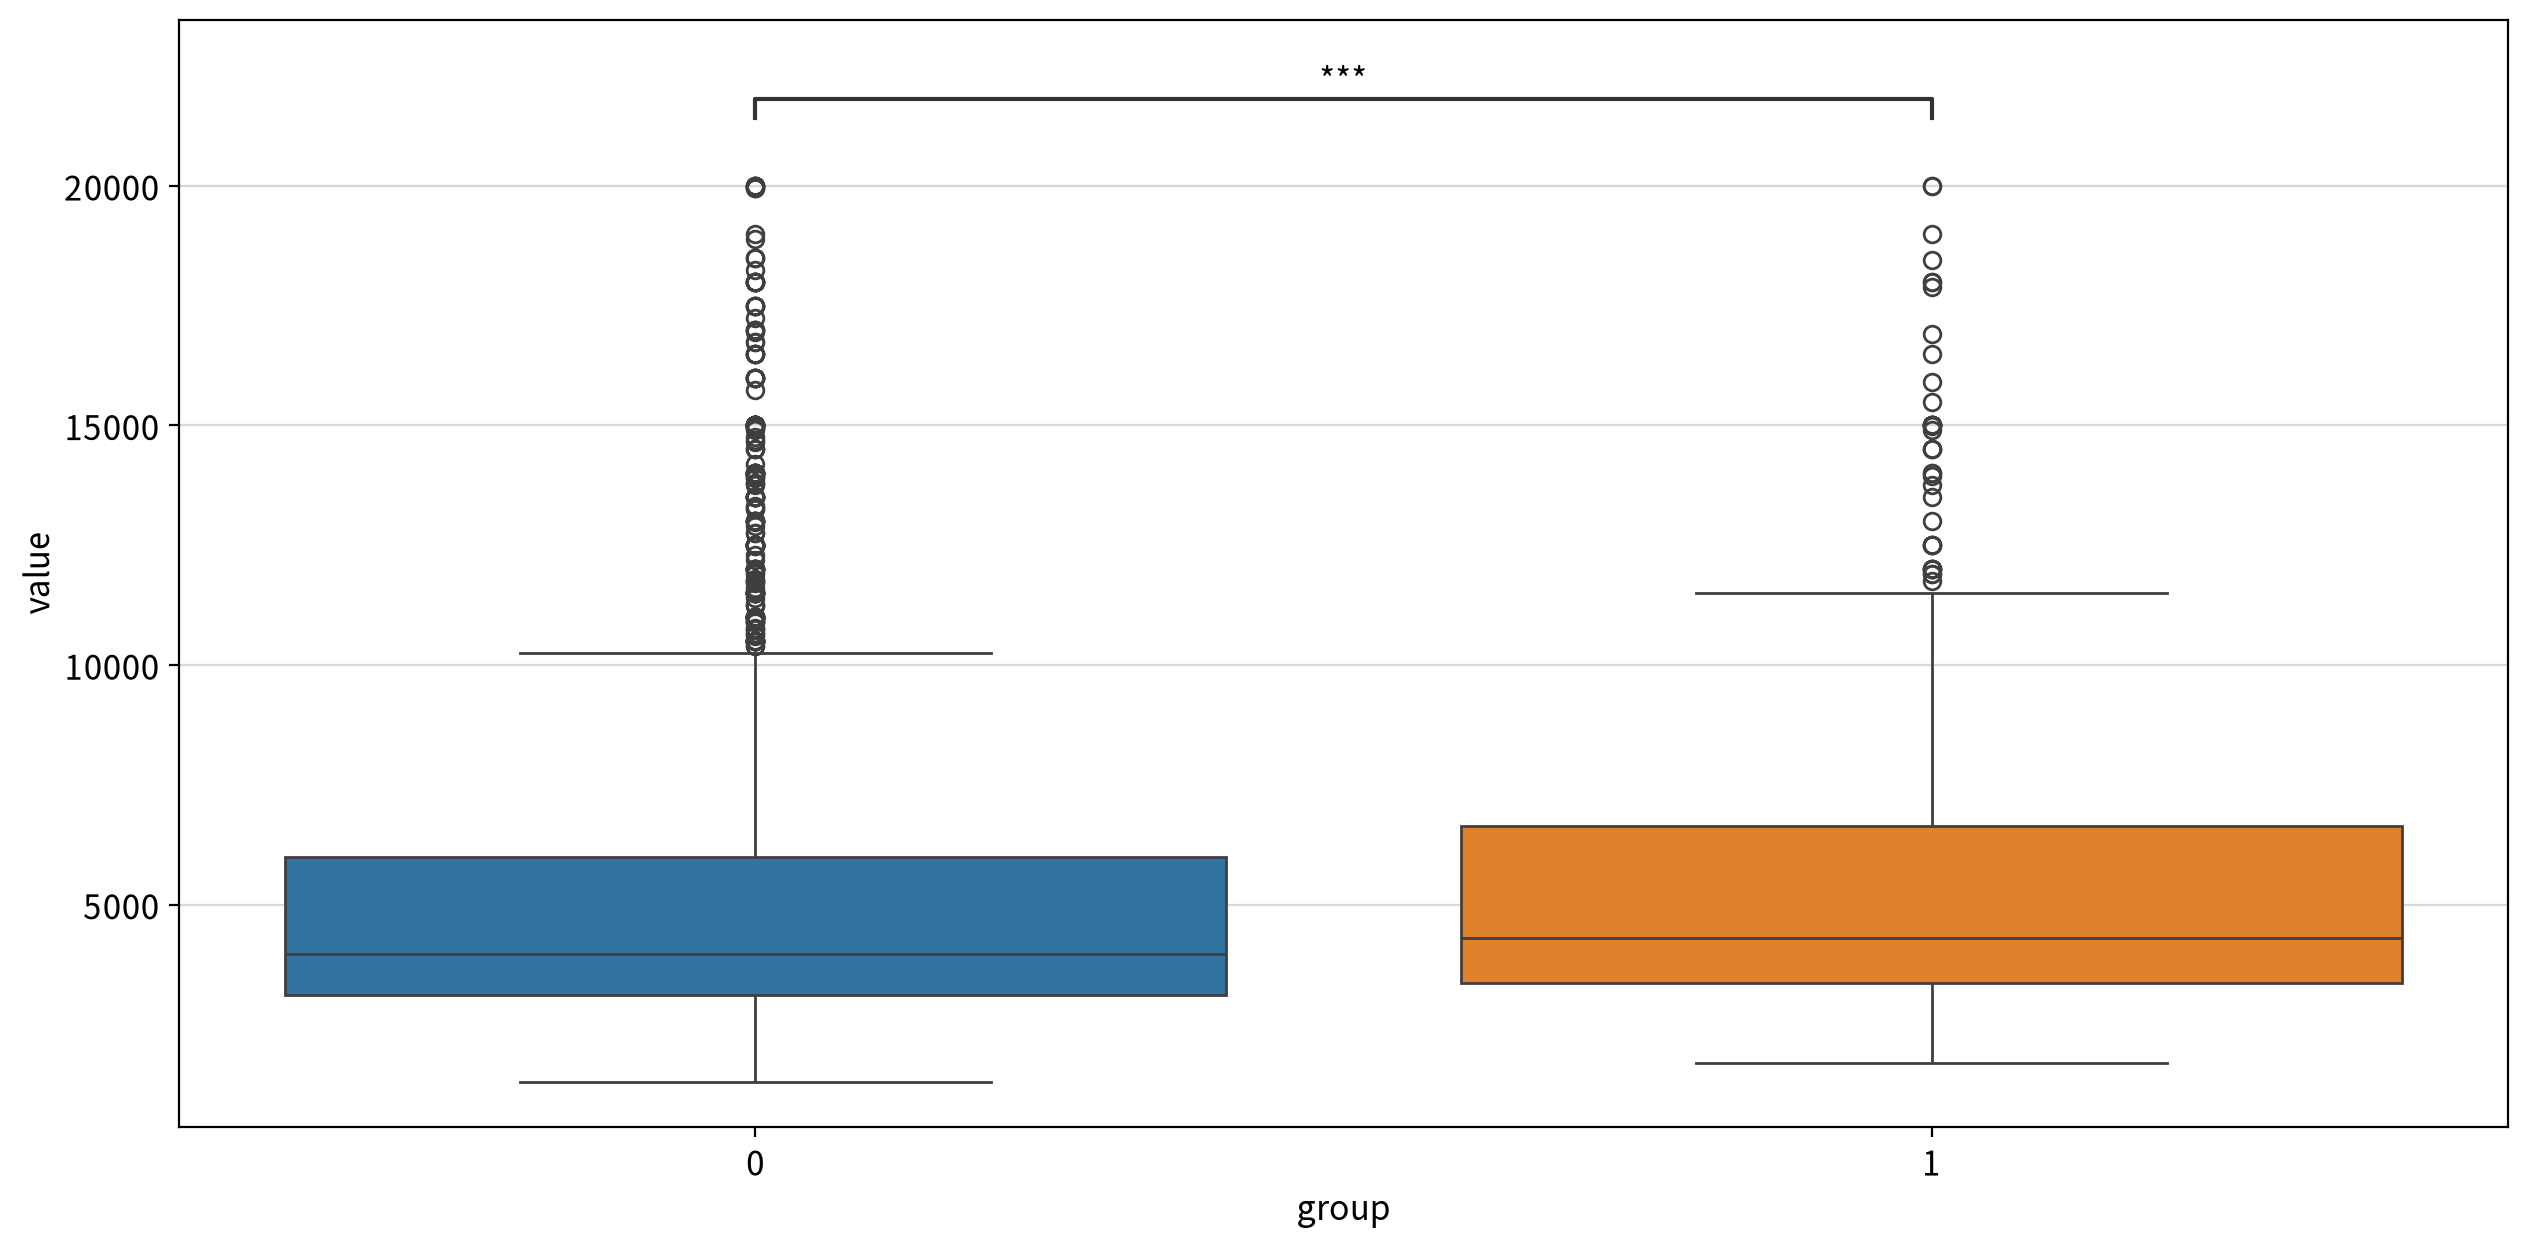

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   748924.500    0.000         True  0 ≠ 1
                    less        748924.500    0.000         True  0 < 1
                    greater     748924.500    1.000        False  0 ≤ 1

##### ▶︎ has_doorman(도어맨 배치 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.051e-02 U_stat=1.174e+06


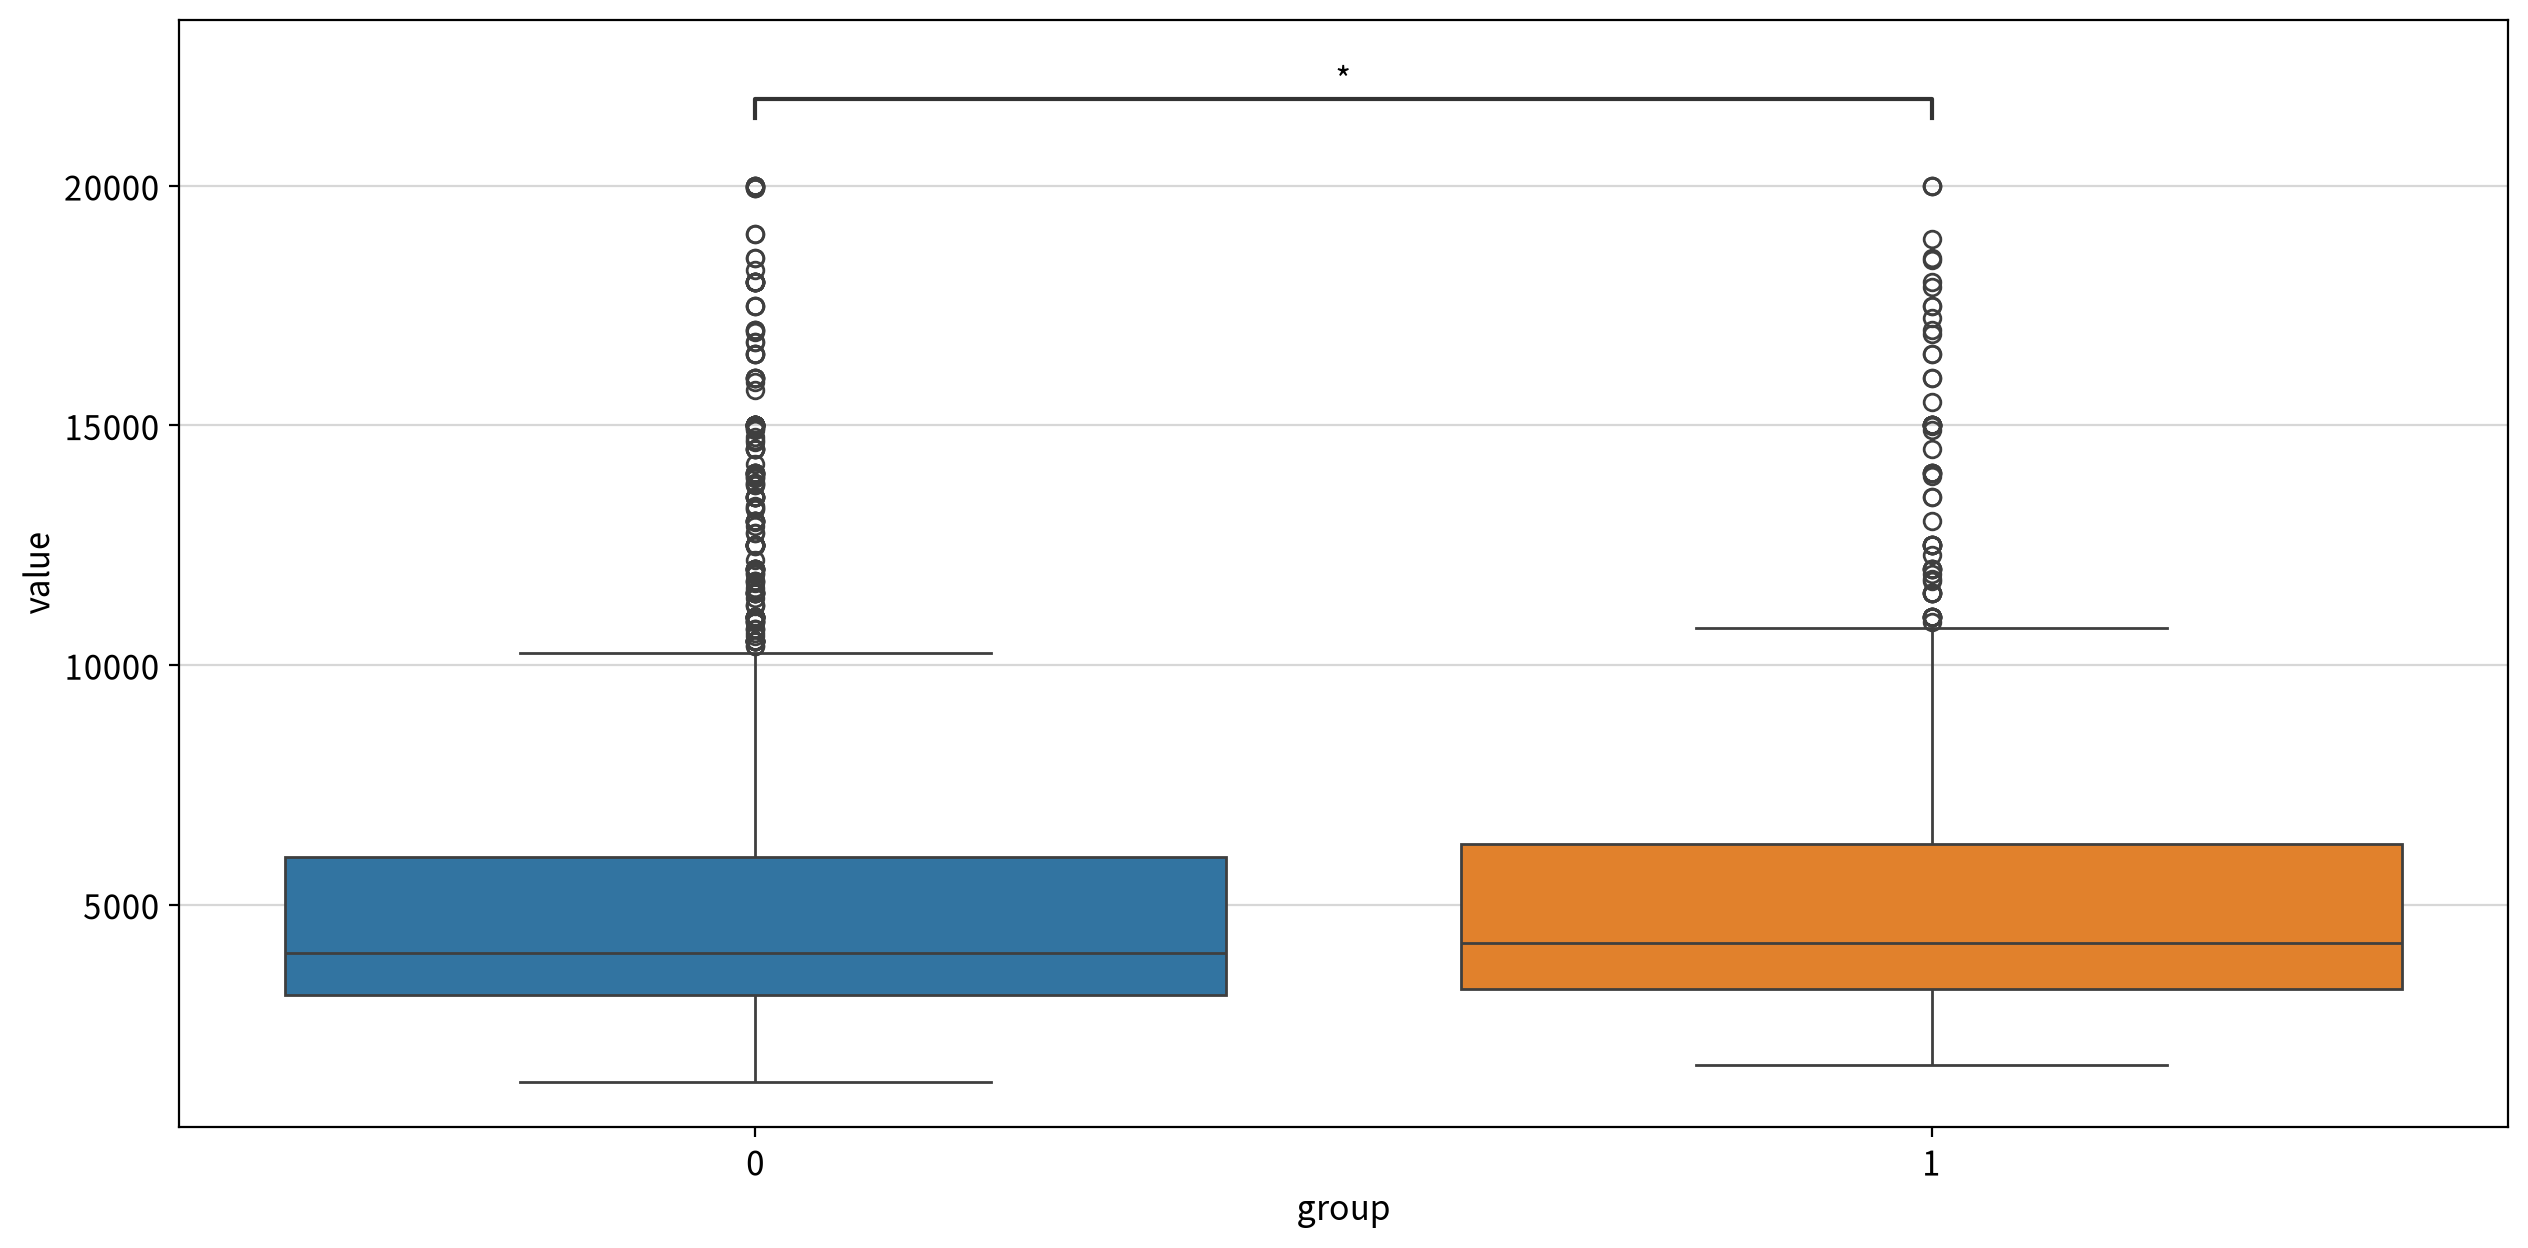

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1173977.000    0.011         True  0 ≠ 1
                    less        1173977.000    0.005         True  0 < 1
                    greater     1173977.000    0.995        False  0 ≤ 1

##### ▶︎ has_elevator(엘리베이터 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.785e-04 U_stat=1.188e+06


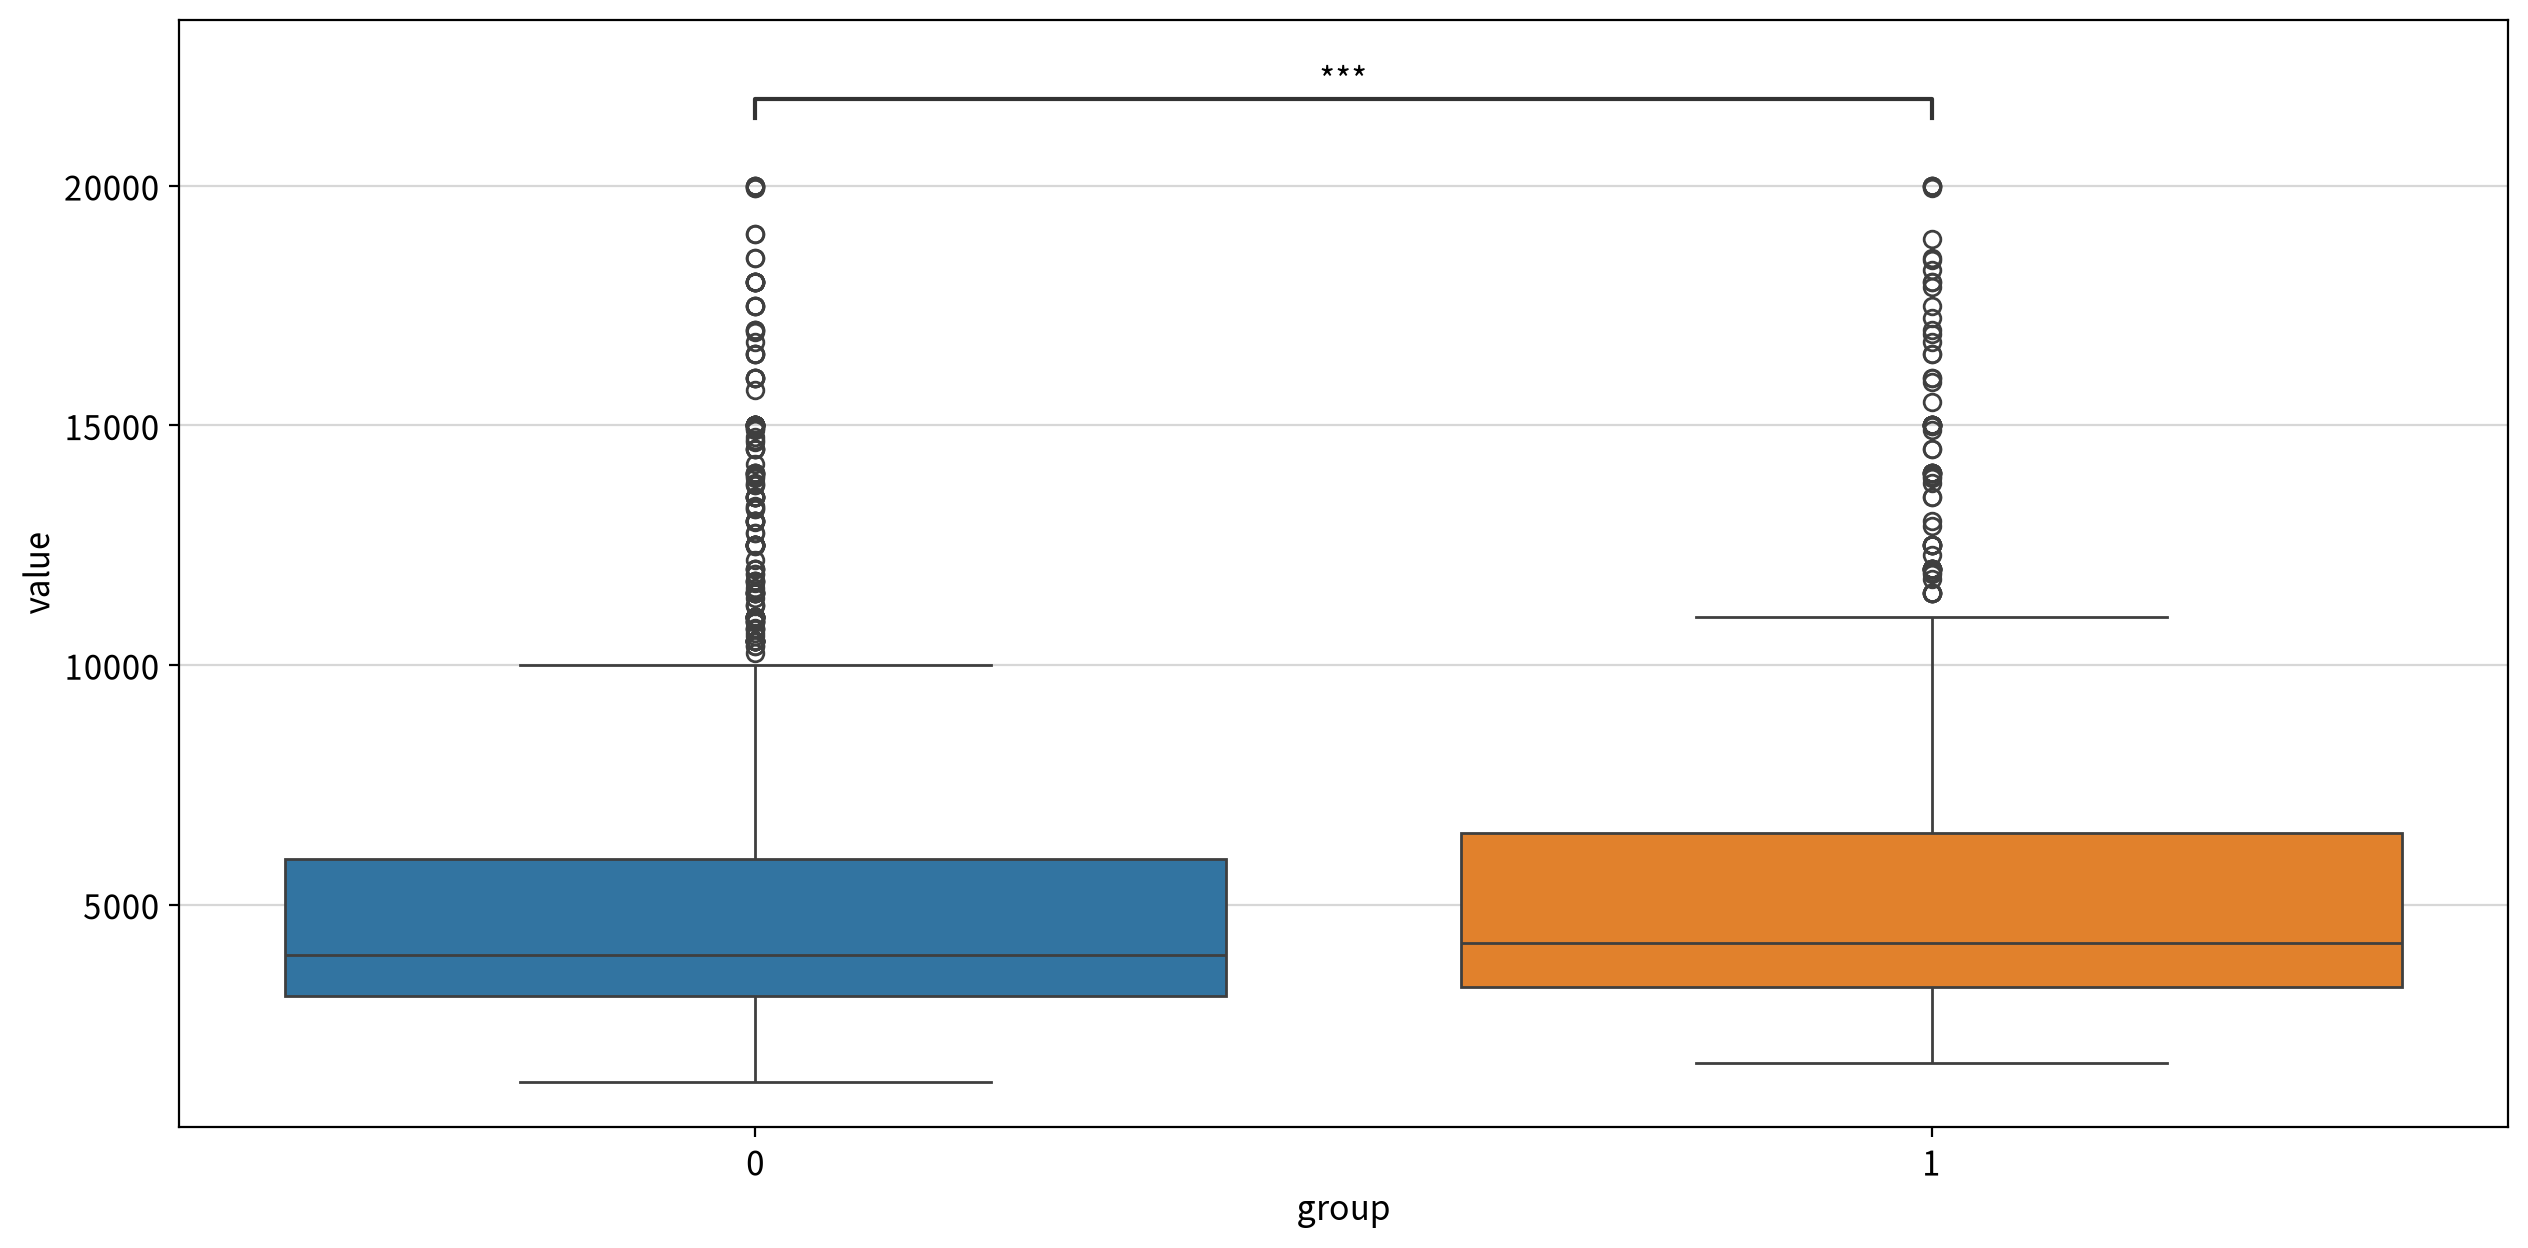

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1188398.500    0.001         True  0 ≠ 1
                    less        1188398.500    0.000         True  0 < 1
                    greater     1188398.500    1.000        False  0 ≤ 1

##### ▶︎ has_dishwasher(식기세척기 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.400e-04 U_stat=8.466e+05


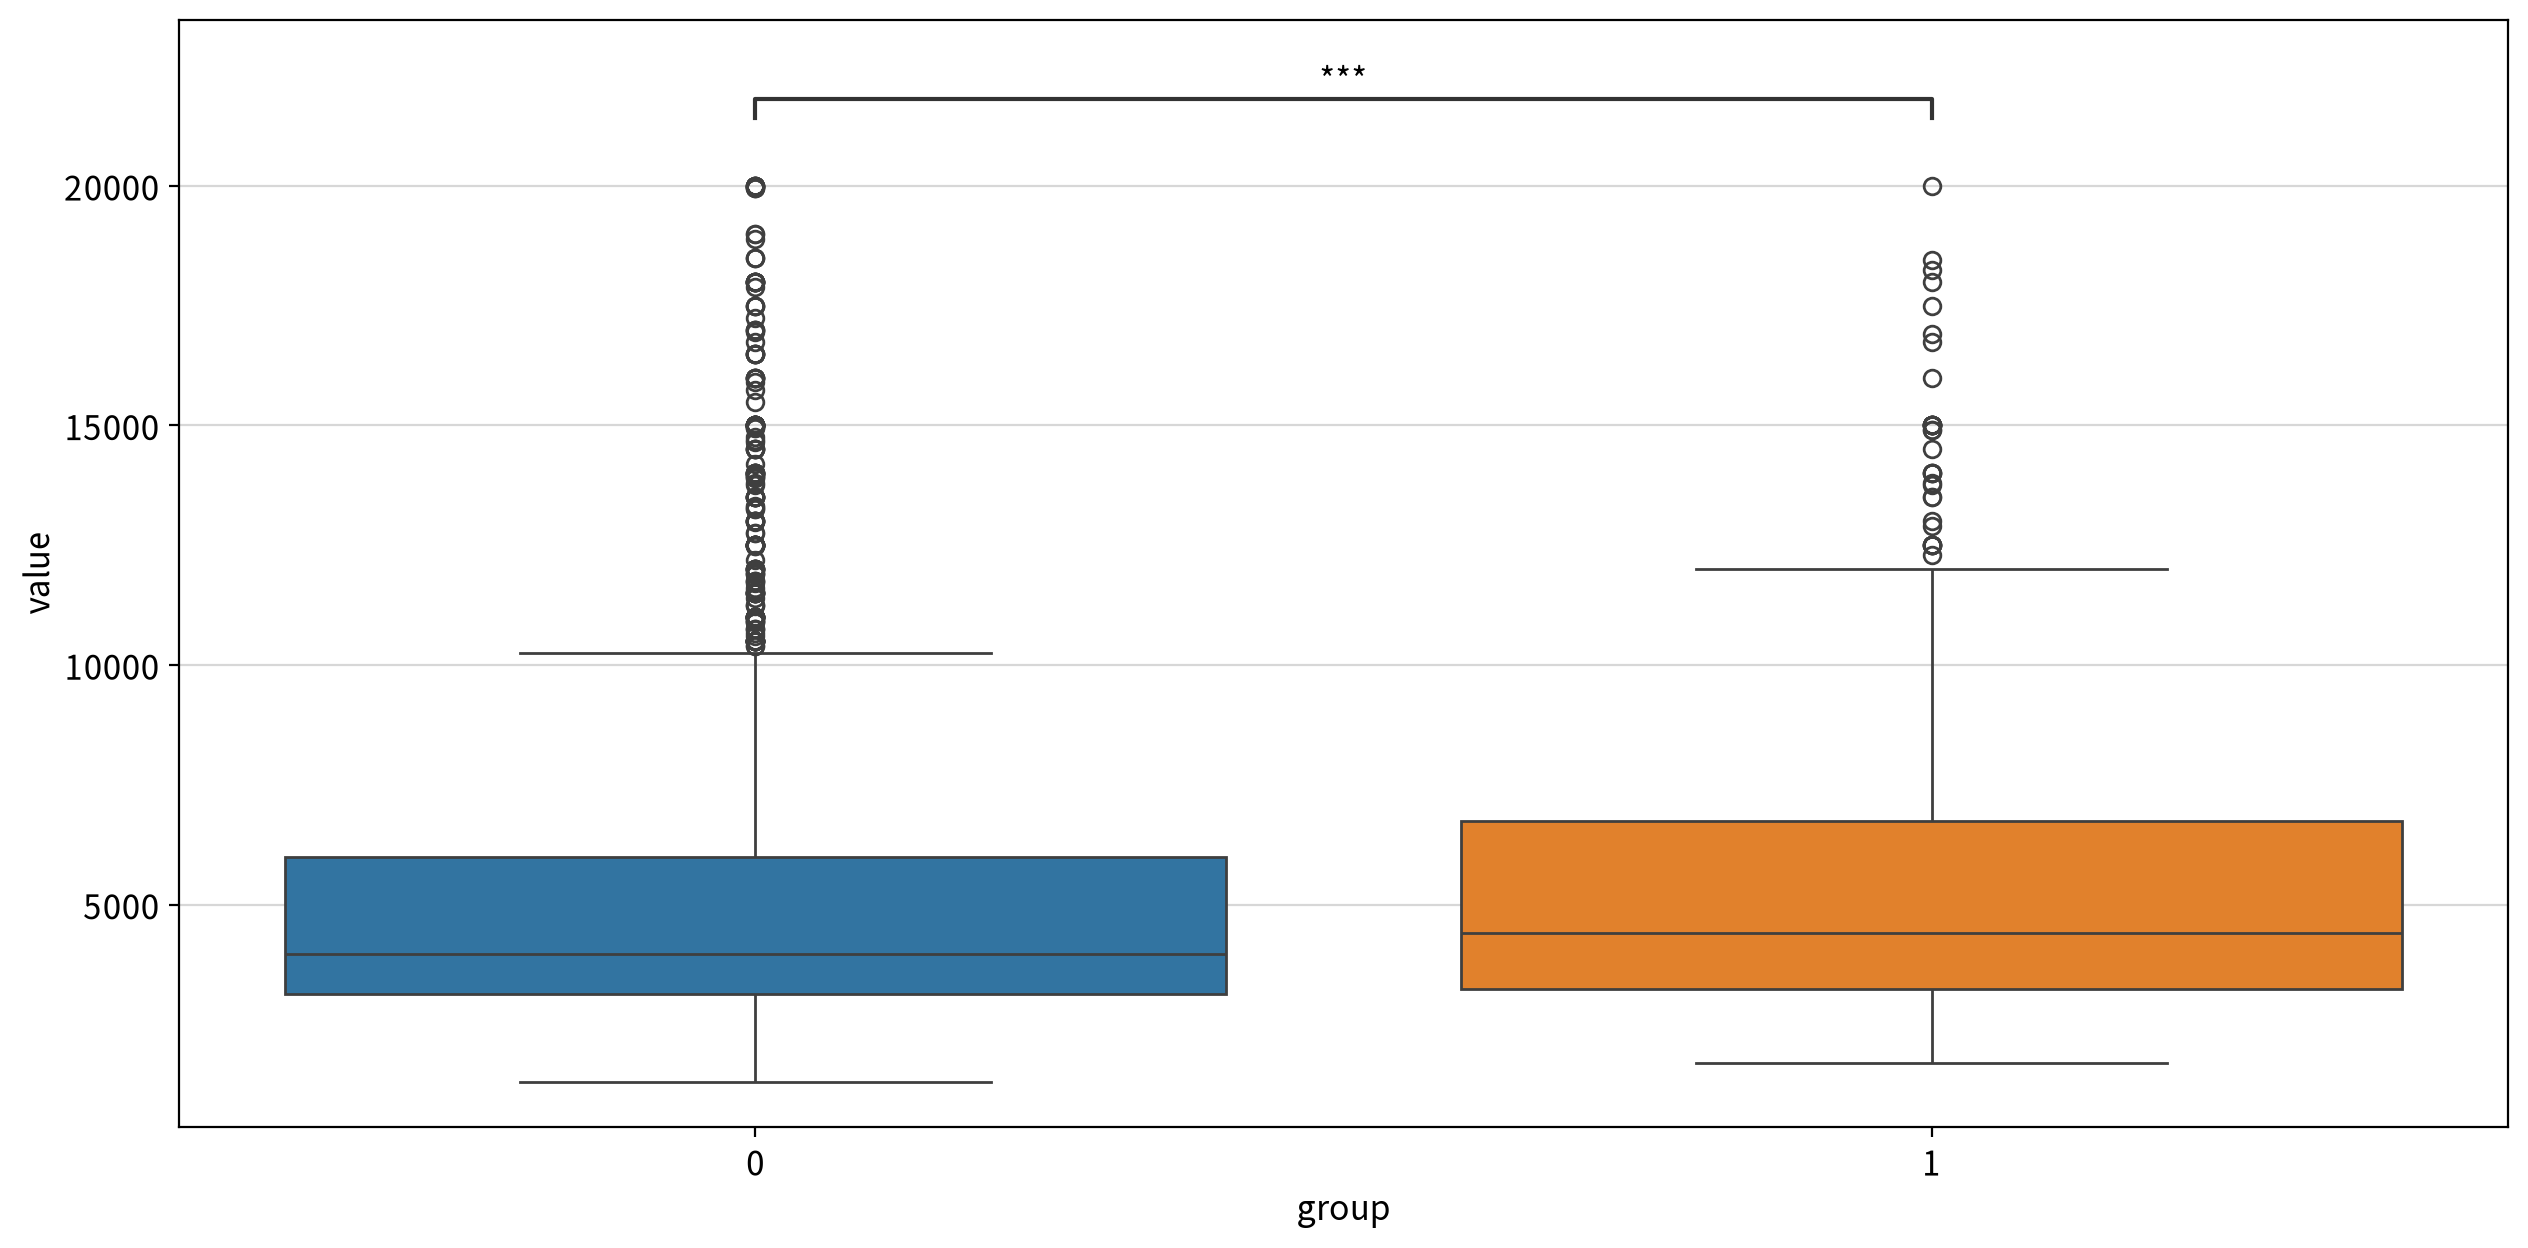

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   846552.000    0.000         True  0 ≠ 1
                    less        846552.000    0.000         True  0 < 1
                    greater     846552.000    1.000        False  0 ≤ 1

##### ▶︎ has_patio(파티오(테라스·발코니) 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.701e-02 U_stat=2.972e+05


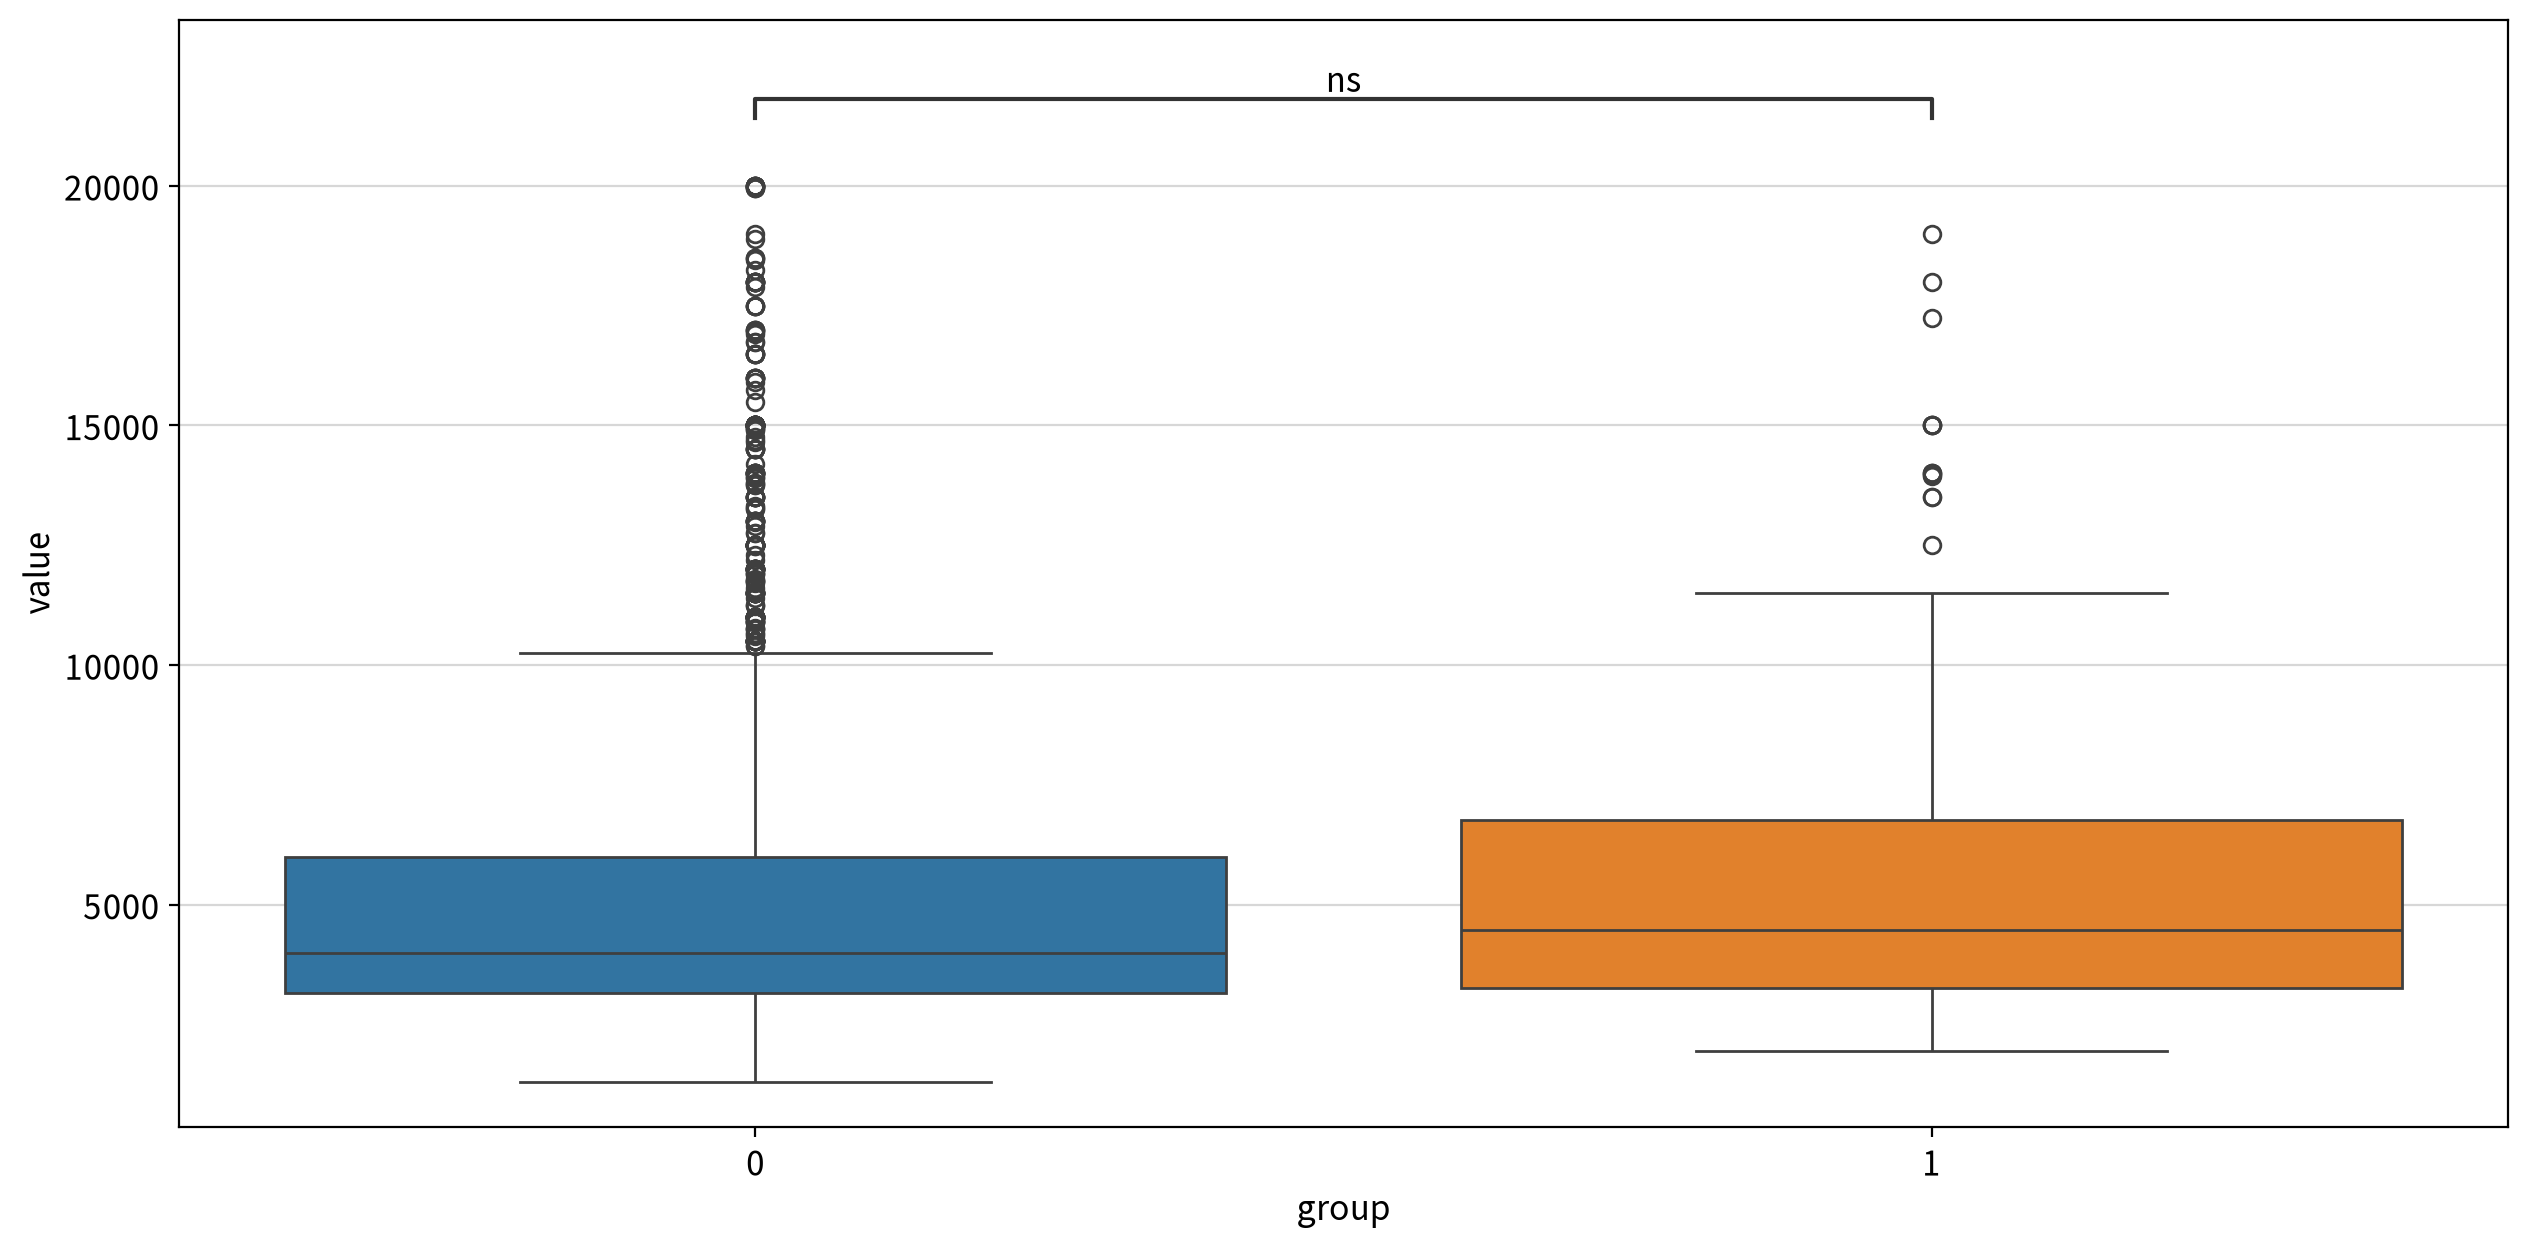

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   297217.500    0.057        False  0 = 1
                    less        297217.500    0.029         True  0 < 1
                    greater     297217.500    0.972        False  0 ≤ 1

##### ▶︎ has_gym(건물 내 헬스장 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.052e-02 U_stat=8.462e+05


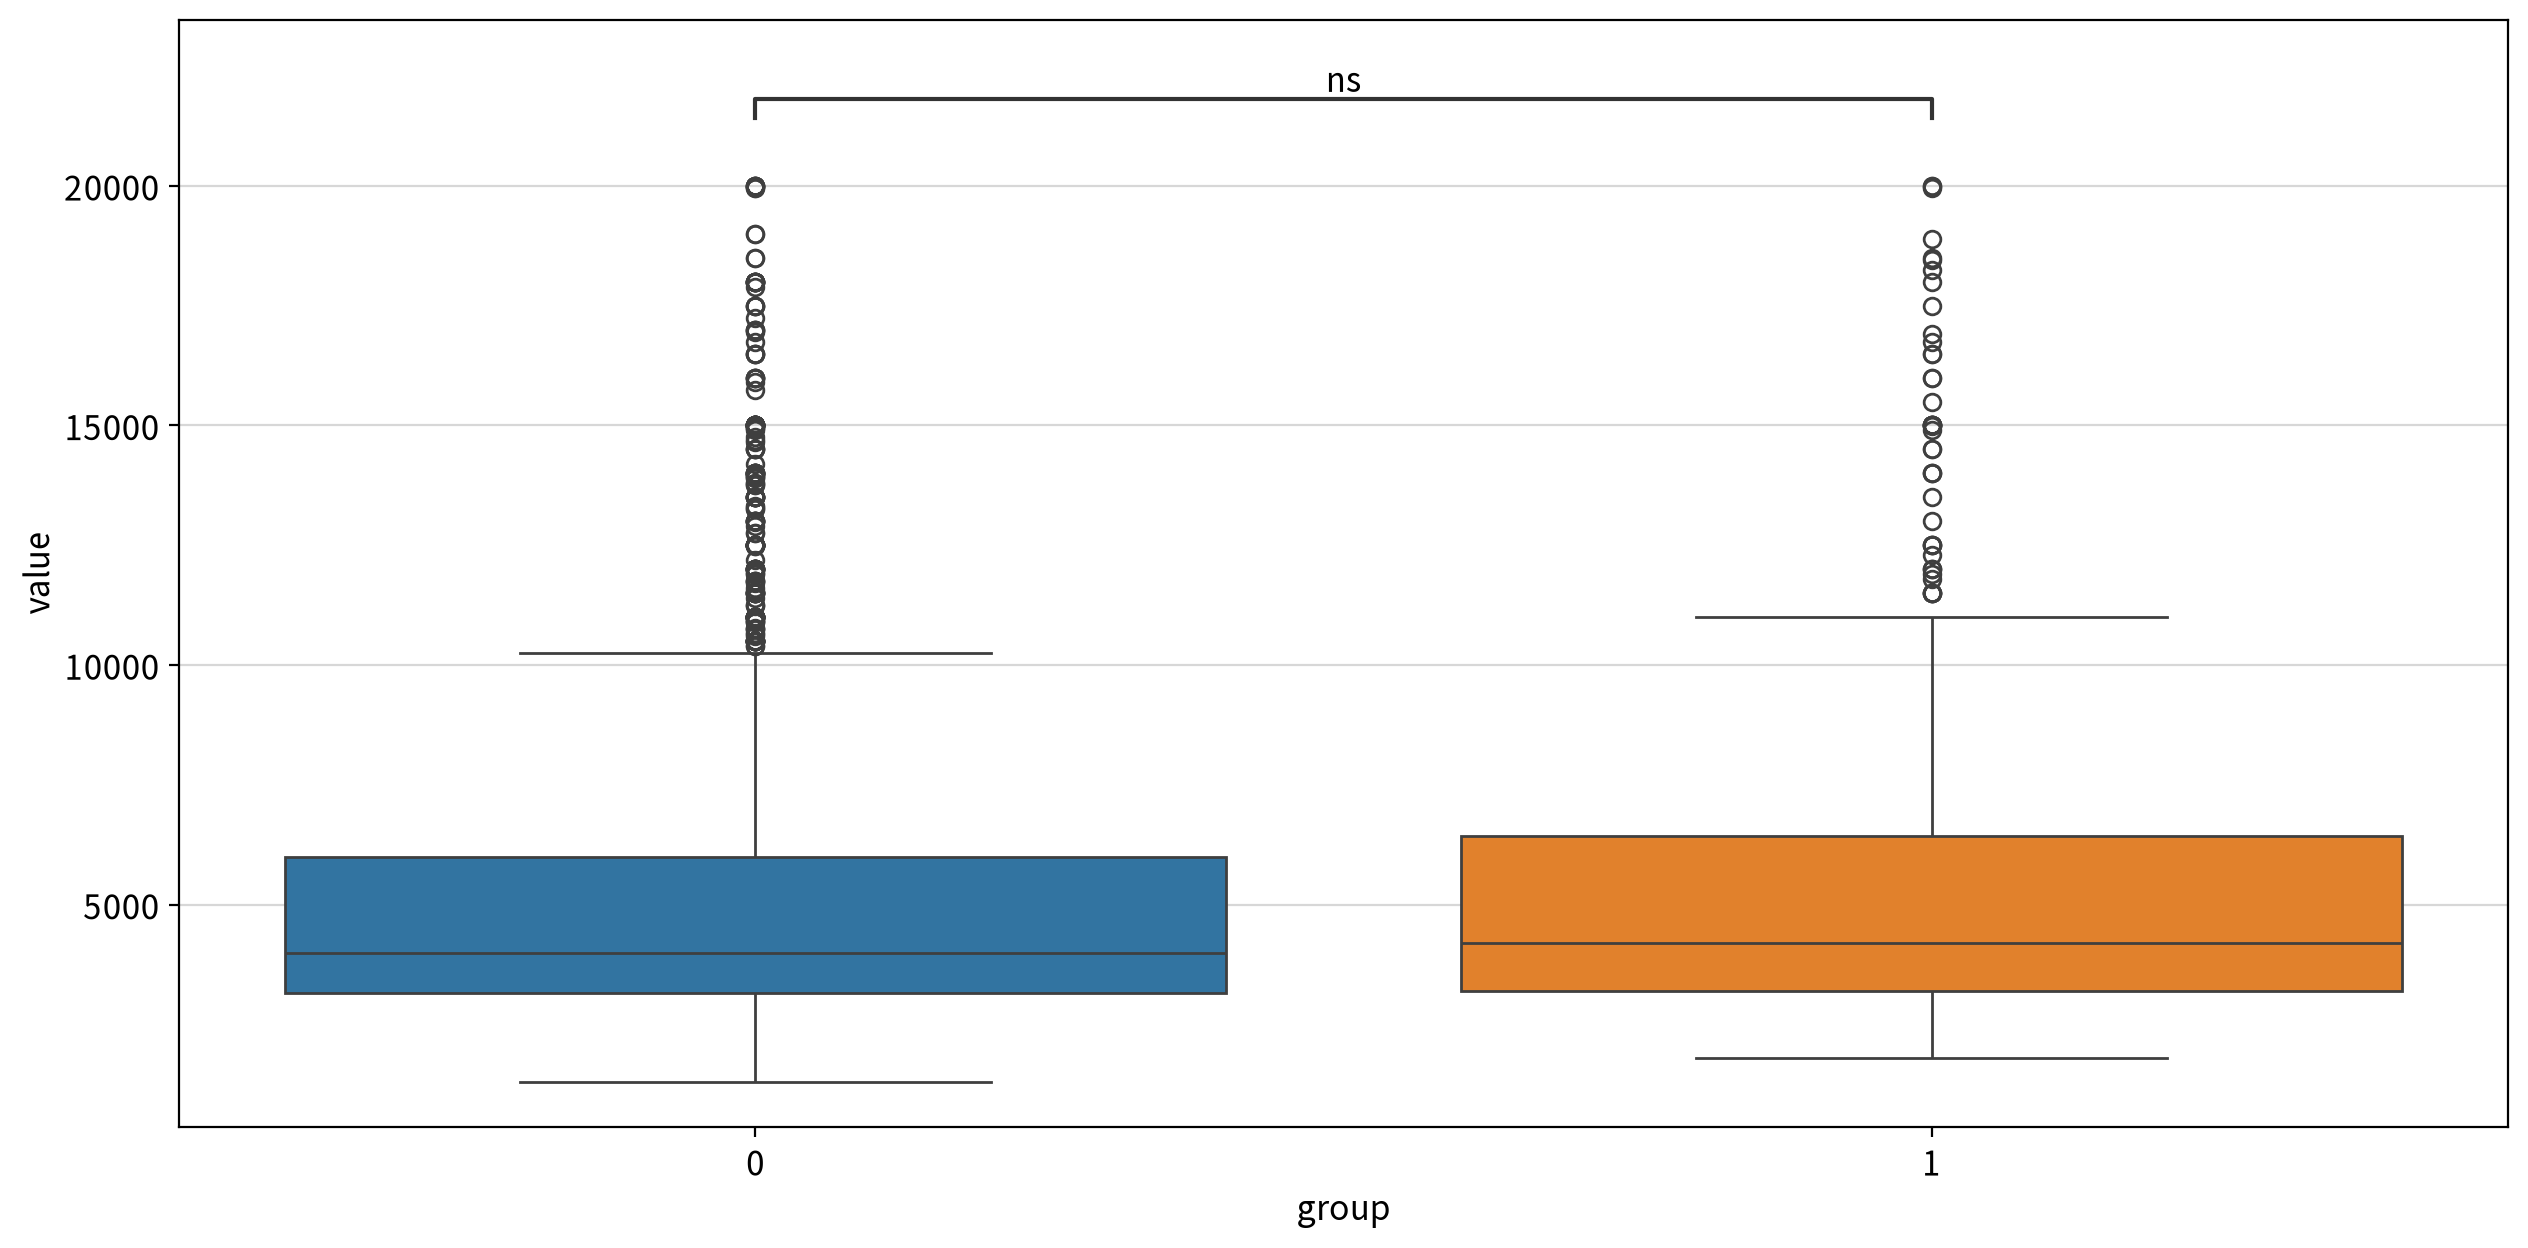

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   846166.500    0.051        False  0 = 1
                    less        846166.500    0.025         True  0 < 1
                    greater     846166.500    0.975        False  0 ≤ 1

In [18]:
for n in nominal_cols:
    ## 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) == 2:
        ## 빈 줄 출력용
        print()

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        ## 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
        wide_df = my_prep.long2wide(df, hue=n, values=target)
        display(my_stats.test_independent(wide_df,
                    group1=wide_df.columns[0], group2=wide_df.columns[1]))

**검정 결과**

- 현재 사용한 Mann-Whitney U test의 출력 결과에 효과크기가 포함되어 있지 않아, 이 결과만으로는 효과크기를 확인할 수 없다.

| 변수 | 검정 | 통계량 | p-value | 판단 | 관련 가설 |
| ------ | ------------------------------------- | ---------- | ------------- | ------------------- | ----------- |
| `no_fee` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 1501349.0 | **.595** (양측) | **차이 없음** (α = .05) | H3 - **기각** |
| `has_roofdeck` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 767120.5 | **.057** (양측) | **차이 없음** (α = .05) | H3 - **기각** |
| `has_washer_dryer` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 748924.5 | **< .001** (양측) | **차이 있음** (α = .05) | H3 - **채택** |
| `has_doorman` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 1173977.0 | **.011** (양측) | **차이 있음** (α = .05) | H3 - **채택** |
| `has_elevator` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 1188398.5 | **.001** (양측) | **차이 있음** (α = .05) | H3 - **채택** |
| `has_dishwasher` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 846552.0 | **< .001** (양측) | **차이 있음** (α = .05) | H3 - **채택** |
| `has_patio` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 297217.5 | **.057** (양측) | **차이 없음** (α = .05) | H3 - **기각** |
| `has_gym` | Mann-Whitney U (정규성 위배로 비모수 검정 자동 선택) | U = 846166.5 | **.051** (양측) | **차이 없음** (α = .05) | H3 - **기각** |

- `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`는 p < .05로 나타나 편의시설 보유 여부에 따른 `rent` 차이가 통계적으로 유의하였다
- `no_fee`, `has_roofdeck`, `has_patio`, `has_gym`은 p > .05로 나타나 보유 여부에 따른 `rent`차이가 통계적으로 유의하지 않았다
- 특히 no_fee는 p = .595로 다른 변수에 비해 유의확률이 크게 나타나, 이후 다변량 모형에서 다른 변수를 통제한 뒤 계수의 유의성을 다시 확인한다

##### 3) ANOVA (x: 3집단 명목형 독립변수 → y: 종속변수)

- 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.

In [19]:
for n in nominal_cols:
    ## 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) >= 3:
        print() ## 빈 줄 출력용

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        display(my_stats.anova_oneway(df, y=target, between=n))
        
        ## 사후검정
        display(my_stats.posthoc_oneway(df, y=target, between=n, plot=False))

##### ▶︎ neighborhood(매물이 속한 세부 동네명) → rent

C:\백업파일\코딩공부\helpers\my_stats.py:88: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = normaltest(data[c].dropna())


,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,neighborhood,31,105.321,37.699,0.000,0.128,Medium


C:\백업파일\코딩공부\helpers\my_stats.py:88: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = normaltest(data[c].dropna())
c:\Users\rhdid\AppData\Local\Programs\Python\Python313\Lib\site-packages\pingouin\effsize.py:830: RuntimeWarning: Degrees of freedom <= 0 for slice
  poolsd = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / dof)
c:\Users\rhdid\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effet_size
0,Games-Howell,Battery Park City,Central Harlem,5968.962,2980.765,2988.196,325.901,9.169,153.079,0.000,1.248,True,Large
1,Games-Howell,Battery Park City,Central Park South,5968.962,7506.957,-1537.995,802.293,-1.917,28.868,0.978,-0.499,False,Small
2,Games-Howell,Battery Park City,Chelsea,5968.962,6208.862,-239.900,366.309,-0.655,220.885,1.000,-0.080,False,Negligible
3,Games-Howell,Battery Park City,Chinatown,5968.962,2963.571,3005.390,458.369,6.557,16.015,0.001,1.041,True,Large
4,Games-Howell,Battery Park City,East Harlem,5968.962,2519.550,3449.412,303.589,11.362,122.895,0.000,1.360,True,Large
...,...,...,...,...,...,...,...,...,...,...,...,...,...
491,Games-Howell,Upper West Side,West Harlem,5361.863,2406.000,2955.863,336.542,8.783,1.463,0.169,0.878,False,Large
492,Games-Howell,Upper West Side,West Village,5361.863,5970.970,-609.107,449.374,-1.355,80.866,1.000,-0.180,False,Negligible
493,Games-Howell,Washington Heights,West Harlem,2539.333,2406.000,133.333,325.615,0.409,1.282,1.000,0.162,False,Negligible
494,Games-Howell,Washington Heights,West Village,2539.333,5970.970,-3431.637,441.250,-7.777,74.844,0.000,-1.282,True,Large


**검정 결과**
| 변수 | 검정 | 통계량 | p-value | 판단 | 관련 가설 |
| ------ | ------------------------------------- | ---------- | ------------- | ------------------- | ----------- |
| `neighborhood` | Welch ANOVA (등분산 가정 위배에 대응) | F = 37.699 | **< .001** | **차이 있음** (α = .05) | H4 - **채택** |

- `neighborhood`에 따른 `rent` 차이는 통계적으로 유의하였다(Welch ANOVA, p < .001)
효과크기는 η² = 0.128로 중간 정도의 효과가 나타나, 동네에 따라 임대료 수준에 실질적인 차이가 있는 것으로 판단된다
- Games-Howell 사후검정 결과, 32개 동네 간 총 496개의 쌍별 비교가 이루어졌으며 유의한 조합과 유의하지 않은 조합이 함께 나타났다.
- 따라서 동네별 평균 임대료가 다를 것이라는 H4를 지지하는 결과이지만, 32개 범주를 그대로 사용하면 비교 조합이 지나치게 많아 해석이 복잡하므로 이후 단계에서 지역 변수를 더 단순한 형태로 재구성할 필요가 있다

## #미션3. "월세를 가르는 변수는 무엇인가?"

1. 연속형 독립변수와 종속변수 간의 상관분석 

| 순위 | 변수 | 분석 방법 | 상관계수 | p-value | 방향·강도 | 해석 |
|---:|---|---|---:|---:|---|---|
| 1 | `size_sqft` | Spearman | **0.838** | < .001 | 강한 양의 상관 | 면적이 넓을수록 `rent`가 높은 경향 |
| 2 | `bathrooms` | Spearman | **0.722** | < .001 | 강한 양의 상관 | 욕실 수가 많을수록 `rent`가 높은 경향 |
| 3 | `bedrooms` | Spearman | **0.678** | < .001 | 중간 정도의 양의 상관 | 침실 수가 많을수록 `rent`가 높은 경향 |
| 4 | `floor` | Spearman | **0.300** | < .001 | 약한 양의 상관 | 층수가 높을수록 `rent`가 높은 경향 |
| 5 | `building_age_yrs` | Spearman | **-0.253** | < .001 | 약한 음의 상관 | 건물이 오래될수록 `rent`가 낮은 경향 |
| 6 | `min_to_subway` | Spearman | **-0.083** | < .001 | 매우 약한 음의 상관 | 지하철 도보 시간이 길수록 `rent`가 낮아지는 경향은 있으나 상관의 정도는 매우 약함 |

- `size_sqft`가 `rent`와 가장 강한 양의 상관관계를 보였고, `bathrooms`와 `bedrooms`도 비교적 강한 양의 관계를 보였다.
- `min_to_subway`는 `rent`와 유의한 음의 상관관계가 나타났지만, 상관의 정도는 매우 약했다(coef=-0.083, p<.001)

2. 2집단 명목형 독립변수와 종속변수 간의 상관분석
- 편의시설 8개 변수의 두 집단별 `rent` 분포에서 정규성 가정이 충족되지 않아 'Mann-Whitney U test'를 적용

**편의시설별 검정 결과표**
| 변수 | 검정 | 통계량 | p-value | 판단 | 효과크기 |
|---|---|---:|---:|---|---|
| `no_fee` | Mann-Whitney U | U = 1501349.0 | **.595** | 차이 없음 | — |
| `has_roofdeck` | Mann-Whitney U | U = 767120.5 | **.057** | 차이 없음 | — |
| `has_washer_dryer` | Mann-Whitney U | U = 748924.5 | **< .001** | **차이 있음** | — |
| `has_doorman` | Mann-Whitney U | U = 1173977.0 | **.011** | **차이 있음** | — |
| `has_elevator` | Mann-Whitney U | U = 1188398.5 | **.001** | **차이 있음** | — |
| `has_dishwasher` | Mann-Whitney U | U = 846552.0 | **< .001** | **차이 있음** | — |
| `has_patio` | Mann-Whitney U | U = 297217.5 | **.057** | 차이 없음 | — |
| `has_gym` | Mann-Whitney U | U = 846166.5 | **.051** | 차이 없음 | — |

- `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`는 편의시설 보유 여부에 따라 `rent`에 통계적으로 유의한 차이가 나타났다. 반면 `no_fee`, `has_roofdeck`, `has_patio`, `has_gym`은 유의수준 0.05에서 유의한 차이가 확인되지 않았다
- has_roofdeck(.057), has_patio(.057), has_gym(.051)은 유의수준에 근접한 반면, no_fee는 p=.595로 집단 간 월세 차이를 뒷받침하는 통계적 근거가 가장 약하게 나타났다.

3. 3집단 이상 명목형 독립변수와 종속변수간의 상관분석
- `neighborhood`의 32개 수준에 따른 `rent` 차이를 검정한 결과 Welch ANOVA의 F=37.699, p<.001로 나타나 동네에 따른 임대료 차이는 통계적으로 유의하였다. 효과크기 역시 **η²=0.128(Medium)**으로 중간 정도의 효과가 확인되었다
- 32개 동네에 대한 Games-Howell 사후검정에서는 총 496개의 쌍별 비교가 발생하였으며, 유의한 조합과 유의하지 않은 조합이 함께 나타났다. 일부 동네에서는 표본 수 부족 경고도 확인되었다. - `neighborhood`는 임대료를 설명하는 의미 있는 변수이지만, 32개 수준을 그대로 사용하는 것은 해석과 활용 측면에서 복잡성이 크므로 이후 단계에서 **더 적은 수의 지역 권역으로 재구성**할 필요가 있다

**제외 후보 변수와 근거**
**`no_fee`를 우선적인 제외 후보 변수로 선정한다**
- `no_fee`는 'Mann-Whitney U 검정'에서 p=.595로 편의시설 8개 변수 중 가장 높은 유의확률을 보였으며, 수수료 유무에 따른 `rent` 차이를 뒷받침하는 통계적 근거가 확인되지 않았다. 따라서 이후 모델링 단계에서 제거 전·후의 성능과 계수 변화를 비교한 뒤 최종 제외 여부를 결정한다.
- `neighborhood`는 유의한 차이와 중간 정도의 효과크기가 확인되었으므로 제외 후보가 아니라 재구성 후보로 판단한다

**종합 해석**

| 가설 | 주요 분석 결과 | 판단 |
|---|---|---|
| **H1** 면적·침실 수·욕실 수가 클수록 임대료가 높을 것이다. | `size_sqft`, `bathrooms`, `bedrooms` 모두 `rent`와 뚜렷한 양의 상관관계가 확인됨 | **지지** |
| **H2** 지하철 도보 시간이 길거나 건물이 오래될수록 임대료가 낮을 것이다. | `min_to_subway`, `building_age_yrs` 모두 음의 상관관계가 확인되었으나, `min_to_subway`의 관계는 매우 약함 | **지지** |
| **H3** 편의시설 보유 여부에 따라 임대료에 차이가 있을 것이다. | 일부 편의시설에서만 유의한 차이가 확인되었으며, 특히 `no_fee`는 차이에 대한 근거가 가장 약함 | **부분 지지** |
| **H4** 동네에 따라 평균 임대료가 다를 것이다. | `neighborhood`에 따른 유의한 임대료 차이가 확인되었으나, 32개 수준으로 해석이 복잡함 | **지지** |

> H1·H2·H4는 지지되었으며, H3는 부분적으로 지지되었다. no_fee는 제거, neighborhood는 재구성을 검토한다

---

#### 4-3. 다변량 분석 — 독립변수 간 상관

In [20]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

method   coef  p-value  strength  \
x             y                                                      
bedrooms      bathrooms         Spearman  0.722    0.000    Strong   
              size_sqft         Spearman  0.828    0.000    Strong   
              min_to_subway     Spearman  0.042    0.014      Weak   
              floor             Spearman  0.046    0.006      Weak   
              building_age_yrs  Spearman  0.007    0.682      Weak   
bathrooms     size_sqft         Spearman  0.763    0.000    Strong   
              min_to_subway     Spearman  0.008    0.653      Weak   
              floor             Spearman  0.138    0.000      Weak   
              building_age_yrs  Spearman -0.115    0.000      Weak   
size_sqft     min_to_subway     Spearman -0.009    0.580      Weak   
              floor             Spearman  0.134    0.000      Weak   
              building_age_yrs  Spearman -0.064    0.000      Weak   
min_to_subway floor             Spearman  0.020    0.229      Weak   
              building_age_yrs  Spearman -0.160    0.000      Weak   
floor         building_age_yrs  Spearman -0.408    0.000  Moderate   

                                significant  normality_x  normality_y  \
x             y                                                         
bedrooms      bathrooms                True        False        False   
              size_sqft                True        False        False   
              min_to_subway            True        False        False   
              floor                    True        False        False   
              building_age_yrs        False        False        False   
bathrooms     size_sqft                True        False        False   
              min_to_subway           False        False        False   
              floor                    True        False        False   
              building_age_yrs         True        False        False   
size_sqft     min_to_subway           False        False        False   
              floor                    True        False        False   
              building_age_yrs         True        False        False   
min_to_subway floor                   False        False        False   
              building_age_yrs         True        False        False   
floor         building_age_yrs         True        False        False   

                                linearity  influential  
x             y                                         
bedrooms      bathrooms             False         True  
              size_sqft             False         True  
              min_to_subway          True         True  
              floor                 False         True  
              building_age_yrs      False        False  
bathrooms     size_sqft              True         True  
              min_to_subway         False         True  
              floor                  True         True  
              building_age_yrs      False         True  
size_sqft     min_to_subway         False         True  
              floor                 False         True  
              building_age_yrs      False         True  
min_to_subway floor                  True         True  
              building_age_yrs      False         True  
floor         building_age_yrs      False         True

,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs
bedrooms,1.000,0.722,0.828,0.042,0.046,0.007
bathrooms,0.722,1.000,0.763,0.008,0.138,-0.115
size_sqft,0.828,0.763,1.000,-0.009,0.134,-0.064
min_to_subway,0.042,0.008,-0.009,1.000,0.020,-0.160
floor,0.046,0.138,0.134,0.020,1.000,-0.408
building_age_yrs,0.007,-0.115,-0.064,-0.160,-0.408,1.000


,max-y,max-coef,count,columns
x,,,,
bedrooms,size_sqft,0.828,2,"size_sqft, bathrooms"
size_sqft,bedrooms,0.828,2,"bedrooms, bathrooms"
bathrooms,size_sqft,0.763,2,"size_sqft, bedrooms"
building_age_yrs,floor,-0.408,0,-
floor,building_age_yrs,-0.408,0,-
min_to_subway,building_age_yrs,-0.160,0,-


**해석**

- **Strong 구간(|ρ| ≥ 0.7)의 쌍:** `bedrooms`–`size_sqft`(+0.828), `bathrooms`–`size_sqft`(+0.763), `bedrooms`–`bathrooms`(+0.722)
- **공통 구조:** `bedrooms`·`bathrooms`·`size_sqft`는 모두 **주택의 크기와 공간 규모**를 나타내는 변수로, 서로 강한 양의 상관관계를 보이며 하나의 변수로 묶인다
- **`size_sqft`가 대표 변수 후보다.** 세 변수 중 `bedrooms`, `bathrooms` 모두와 강한 관계를 가지며, 앞선 분석에서도 `rent`와 가장 높은 상관관계(ρ=0.838)를 보였다
- **추가적으로 확인된 관계:** `floor`–`building_age_yrs`는 −0.408로 중간 정도의 음의 상관관계를 보였으나, Strong 수준의 중복 관계는 아니다
- **중복 관계가 거의 없는 변수:** `min_to_subway`, `floor`, `building_age_yrs`는 다른 변수와 강한 상관관계가 없어 비교적 독립적인 정보를 가진다
- `bedrooms`·`bathrooms`·`size_sqft`를 모두 모델에 사용하면 비슷한 정보가 중복될 수 있으므로, **`size_sqft`를 대표 변수로 우선 검토하고 나머지 변수의 정보는 파생변수 활용 가능성을 검토한다**

## 미션 4. "겹치는 축은 무엇인가?"

- 연속형 독립변수 간 Spearman 상관분석 결과, `bedrooms`·`bathrooms`·`size_sqft`가 서로 강한 양의 상관관계를 보여 하나의 변수군으로 묶였다

| 변수 조합 | 상관계수 | 강도 |
|---|---:|---|
| `bedrooms` ↔ `size_sqft` | **0.828** | Strong |
| `bathrooms` ↔ `size_sqft` | **0.763** | Strong |
| `bedrooms` ↔ `bathrooms` | **0.722** | Strong |

1. `bedrooms`, `bathrooms`, `size_sqft`는 모두 **주택의 크기와 공간 구성**이라는 비슷한 정보를 담고 있다. 세 변수를 동시에 모델에 투입하면 중복된 정보로 인해 **다중공선성이 발생할 가능성**이 있으며, 각 변수의 독립적인 영향과 회귀계수를 해석하기 어려워질 수 있다.

2. 세 변수 중에서는 `size_sqft`를 **대표 변수로 우선 선정한다**
- `size_sqft`는 `bedrooms`, `bathrooms` 모두와 강한 상관관계를 가지며, 종속변수 분석에서도 `rent`와 **가장 높은 상관관계(ρ=0.838)**를 보였다. 또한 침실·욕실 개수보다 주택의 전체적인 공간 규모를 직접적으로 나타내는 변수이므로 대표성이 높다고 판단하였다

3. `bedrooms`와 `bathrooms`를 단순히 제거하기보다 공간 구성 정보를 나타내는 **파생변수**로 활용할 수 있다
- 면적 대비 침실 수, 면적 대비 욕실 수와 같은 변수를 생성하면 전체 면적과 중복되는 정보를 줄이면서도 **주택 내부 공간 구성의 특성**을 유지할 수 있다
    - `bedrooms`, `bathrooms` 변수는 제외 후보로 선정한다

### 모델에 넣을 1순위 변수

> **`size_sqft`**

**선정 근거**  
- `rent`와 가장 강한 양의 상관관계(ρ=0.838)를 보였다
- `bedrooms`, `bathrooms`와 강하게 묶이는 공간 규모 변수군의 대표성이 높다
- 전체 주택 면적을 직접 나타내므로 모델 해석이 비교적 명확하다
    - `floor`와 `building_age_yrs`는 ρ=-0.408로 중간 정도의 음의 상관관계가 있었지만, **강한 중복 관계로 판단할 수준은 아니므로 현재 단계에서는 둘 다 유지**하는 것으로 판단

---

#### 4-4. 파생변수 생성

| 의미 | 계산식 | 파생 변수명 |
|---|---|---|
| 방 하나당 면적 | `size_sqft / (bedrooms + bathrooms)` | `sqft_per_room` |
| 편의시설 개수 | `has_*` 7개 합계 | `amenity_count` |
| 동네 평균 대비 면적 | `size_sqft / neighborhood 평균 size_sqft` | `relative_size` |
| 동네 평균 대비 층 | `floor / neighborhood 평균 floor` | `relative_floor` |
| 면적 대비 침실 수 | `bedrooms / size_sqft` | `bedroom_density` |
| 면적 대비 욕실 수 | `bathrooms / size_sqft` | `bathroom_density` |
| 방 하나당 면적의 동네 평균 대비 수준 | `sqft_per_room / neighborhood 평균 sqft_per_room` | `relative_sqft_per_room` |

#### 4-4. 파생변수 점검 
- 1차 파생변수의 결측치와 무한대(inf) 확인 후 제거
- 2차 파생변수 생성 후 점검

In [24]:
display(Markdown("### 분모로 사용한 변수의 최솟값 확인"))

print("bedrooms + bathrooms 최솟값:",
      (df["bedrooms"] + df["bathrooms"]).min())

print("동네별 size_sqft 평균의 최솟값:",
      df.groupby("neighborhood")["size_sqft"].transform("mean").min())

print("동네별 floor 평균의 최솟값:",
      df.groupby("neighborhood")["floor"].transform("mean").min())

print("size_sqft 최솟값:",
      df["size_sqft"].min())


display(Markdown("### 1차 파생변수 범위 확인"))

print(df[[
    "size_per_room",
    "amenity_count",
    "relative_size",
    "relative_floor",
    "bedroom_density",
    "bathroom_density"
]].agg(["min", "max"]))


check = df[[
    "size_per_room",
    "amenity_count",
    "relative_size",
    "relative_floor",
    "bedroom_density",
    "bathroom_density"
]]


display(Markdown("### 파생변수에 결측값이 있는지 확인"))

print(check.isna().sum())


display(Markdown("### 파생변수에 무한대가 있는지 확인"))

print(check.isin([float("inf"), float("-inf")]).sum())

### 분모로 사용한 변수의 최솟값 확인

bedrooms + bathrooms 최솟값: 0.0
동네별 size_sqft 평균의 최솟값: 433.3333333333333
동네별 floor 평균의 최솟값: 2.9375
size_sqft 최솟값: 250


C:\Users\rhdid\AppData\Local\Temp\ipykernel_12412\1172764042.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("neighborhood")["size_sqft"].transform("mean").min())
C:\Users\rhdid\AppData\Local\Temp\ipykernel_12412\1172764042.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("neighborhood")["floor"].transform("mean").min())


### 1차 파생변수 범위 확인

     size_per_room  amenity_count  relative_size  relative_floor  \
min        124.000              0          0.200           0.000   
max            inf              7          4.782           7.941   

     bedroom_density  bathroom_density  
min            0.000             0.000  
max            0.005             0.006  


### 파생변수에 결측값이 있는지 확인

size_per_room       0
amenity_count       0
relative_size       0
relative_floor      0
bedroom_density     0
bathroom_density    0
dtype: int64


### 파생변수에 무한대가 있는지 확인

size_per_room       2
amenity_count       0
relative_size       0
relative_floor      0
bedroom_density     0
bathroom_density    0
dtype: int64


##### 무한대 2건 처리

- `size_per_room`의 분모인 `bedrooms + bathrooms`의 최솟값이 0으로 확인되었으며,
이에 따라 2개 행에서 무한대(inf)가 발생하였다
- 전체 3,512개 행 중 무한대가 발생한 행은 2개로 약 0.057%에 해당하며,
5% 미만이므로 정보 손실이 작다고 판단하여 해당 행을 제거하였다
- 나머지 1차 파생변수에서는 결측값과 무한대가 발생하지 않았다